# ELEC2301 Machine Learning Coursework
## Parts A & B — Precision Agriculture & Battery Thermal Modelling

In [1]:
# Importing necessary libraries for data manipulation, visualization, and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
    mean_squared_error, r2_score, mean_absolute_error,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif

# Setting up visualization parameters and defining paths for figures and data
matplotlib.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', palette='muted')

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
DATA = Path('data')

RANDOM_STATE = 42

# Part A — Precision Agriculture

**Dataset:** `Crops_data.csv` — environmental, soil, and nutrient measurements with crop type labels.

**Objective:** Segment farmland into cropping zones (unsupervised), then build a crop recommendation classifier (supervised) that predicts `Crop Type` from environmental, soil, and nutrient inputs.


## A1 — Exploratory Data Analysis

In [2]:
# Loading dataset / performing explanatory data analysis
crops = pd.read_csv(DATA / 'Crops_data.csv')
print(f"Shape: {crops.shape}")
print(f"\nColumn dtypes:\n{crops.dtypes}")
print(f"\nNull counts:\n{crops.isnull().sum()}")
print(f"\nDescriptive statistics:")
crops.describe()

Shape: (8000, 9)

Column dtypes:
Temperature        float64
Humidity           float64
Moisture           float64
Soil Type           object
Crop Type           object
Nitrogen             int64
Potassium            int64
Phosphorous          int64
Fertilizer Name     object
dtype: object

Null counts:
Temperature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

Descriptive statistics:


,Temperature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.338895,59.210731,43.580862,18.429125,3.916375,18.512500
std,4.478262,8.177366,12.596156,11.852406,5.494807,13.244113
min,20.000000,40.020000,20.000000,0.000000,0.000000,0.000000
25%,27.050000,53.277500,33.967500,9.000000,0.000000,8.000000
50%,30.240000,59.110000,42.250000,14.000000,1.000000,18.000000
75%,33.460000,65.082500,52.950000,26.000000,5.000000,30.000000
max,40.000000,80.000000,70.000000,46.000000,23.000000,46.000000


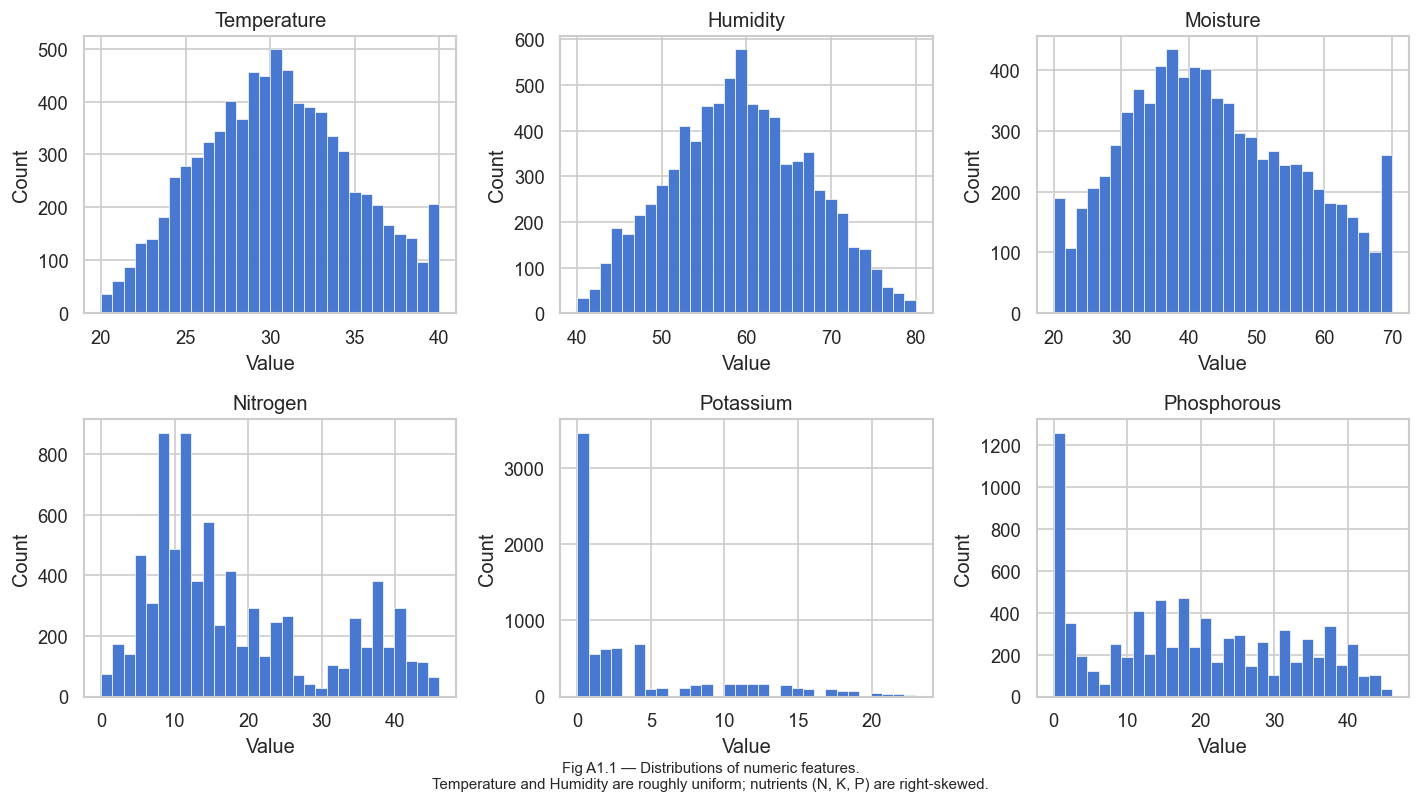

In [3]:
# Visualizing distributions of numeric features
# Note: Temperature and Humidity are roughly uniform; nutrients (N, K, P) are right-skewed.
# This suggests that while environmental conditions are evenly distributed, nutrient levels vary widely, which may impact crop growth and classification.
NUM_FEATURES = ['Temperature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, NUM_FEATURES):
    ax.hist(crops[col], bins=30, edgecolor='white', linewidth=0.4)
    ax.set_title(col)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
fig.suptitle('Fig A1.1 — Distributions of numeric features.\n'
             'Temperature and Humidity are roughly uniform; nutrients (N, K, P) are right-skewed.',
             y=0.02, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'a1_distributions.png', bbox_inches='tight')
plt.show()

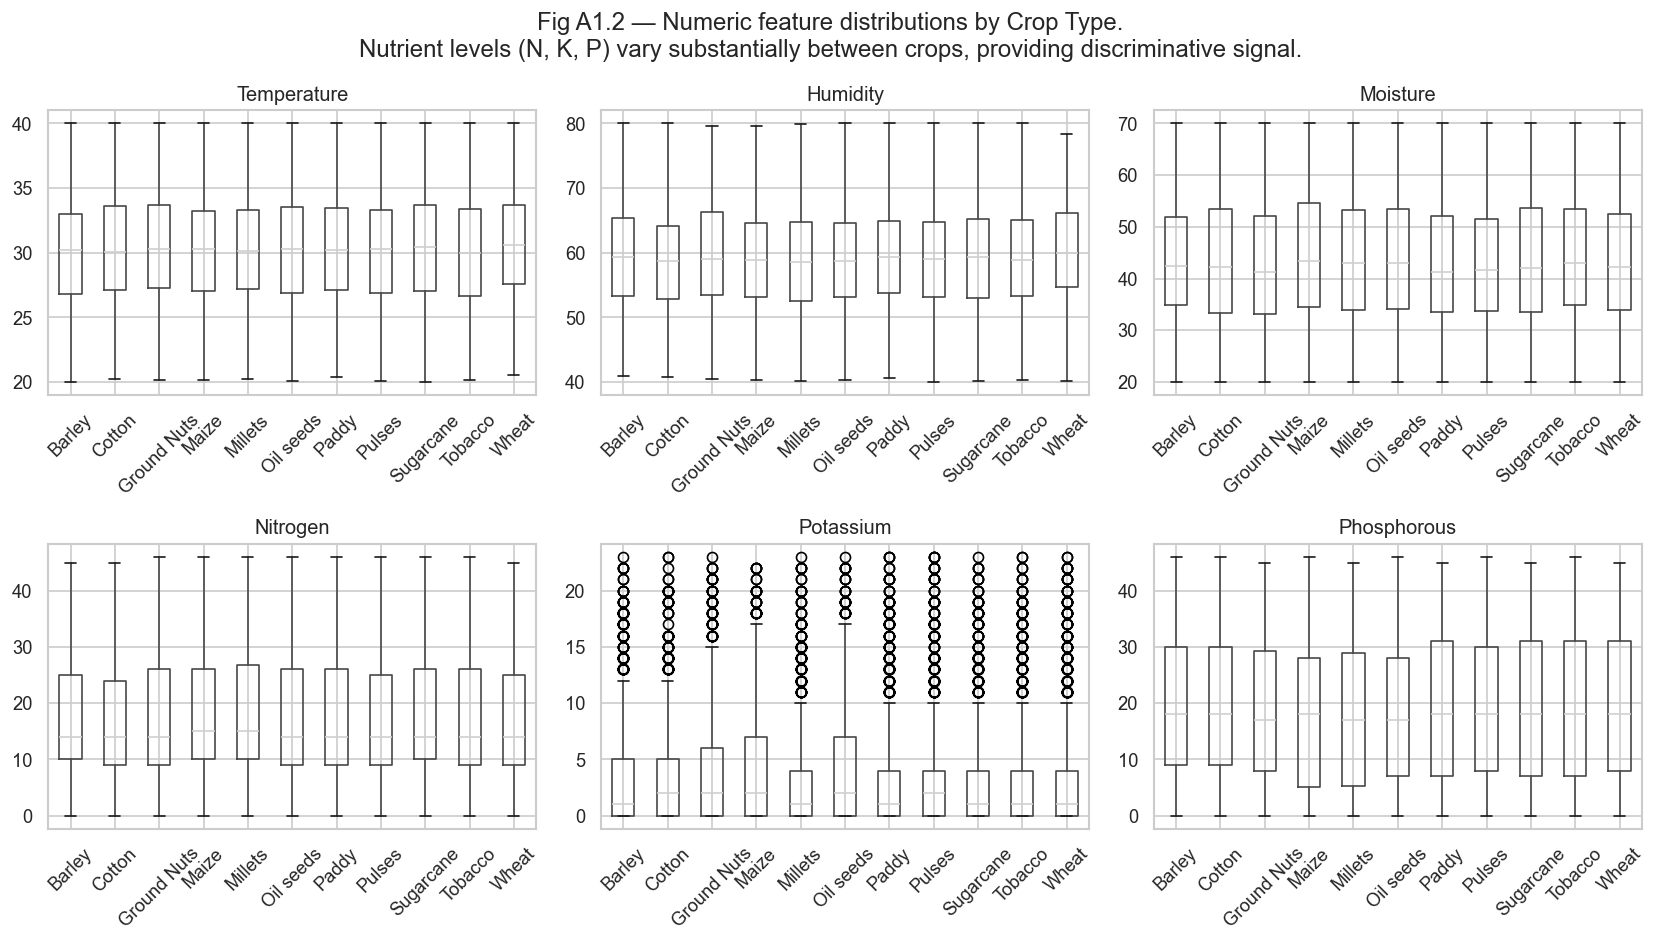

In [4]:
#  boxplots of numeric features by Crop Type
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, NUM_FEATURES):
    crops.boxplot(column=col, by='Crop Type', ax=ax, rot=45)
    ax.set_title(col)
    ax.set_xlabel('')
fig.suptitle('Fig A1.2 — Numeric feature distributions by Crop Type.\n'
             'Nutrient levels (N, K, P) vary substantially between crops, providing discriminative signal.')
plt.tight_layout()
plt.savefig(FIGURES / 'a1_boxplots_by_crop.png', bbox_inches='tight')
plt.show()

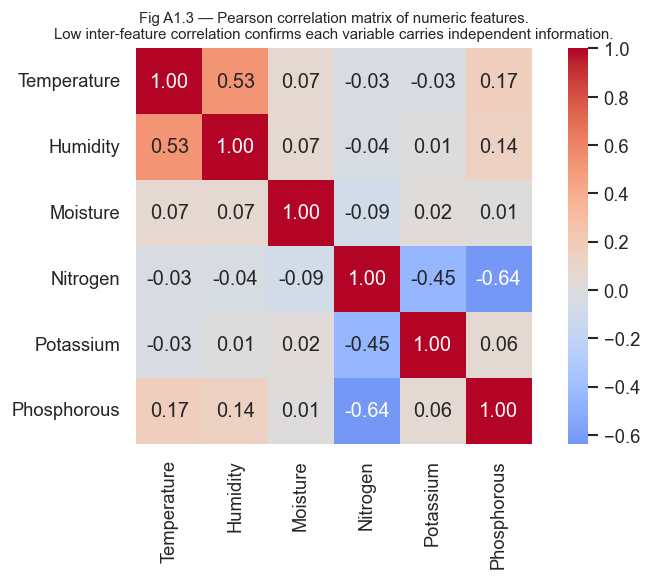

Class balance:
Crop Type
Sugarcane      763
Maize          753
Wheat          747
Ground Nuts    732
Pulses         728
Cotton         722
Millets        718
Tobacco        717
Oil seeds      711
Paddy          706
Barley         703
Name: count, dtype: int64

Soil Type balance:
Soil Type
Clayey    1623
Black     1613
Red       1594
Loamy     1590
Sandy     1580
Name: count, dtype: int64


In [5]:
# Pearson correlation heatmap of numeric features
# Low inter-feature correlation confirms each variable carries independent information.
corr = crops[NUM_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, square=True)
ax.set_title('Fig A1.3 — Pearson correlation matrix of numeric features.\n'
             'Low inter-feature correlation confirms each variable carries independent information.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'a1_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print("Class balance:")
print(crops['Crop Type'].value_counts())
print("\nSoil Type balance:")
print(crops['Soil Type'].value_counts())

**EDA observations:**
- 8,000 samples, no missing values — the data set is clean and does not require imputation.
 - All numerical characteristics are on different scales (Temperature 20–40°C and Phosphorous 0–46 units), requiring standardization before any distance algorithm. 
 - Nutrient characteristics (N, K, P) are right-skewed with many zero values (many crops require a minimal supplementation of certain nutrients). This motivates you to verify whether the deviation affects the model calibration — for tree models it does not, but for KNN with Euclidean distance zero inflation compresses the distances between samples near zero.
 - Classification of crop types is well balanced (703–763 samples per sample), so no weighting of classes or excessive sampling is required.
 - The type of soil is distributed uniformly (1,580–1,623 per type), thereby reducing sampling biases in the various strata.
 - Fertilizer names are excluded from clustering/classification inputs: they are input variables (outputs) and are not environmental input conditions. It would include this and constitute target leakage.
- **Effect of characteristics (box plot, Figure A1.2):** Nitrogen shows the largest spread between crops (ICR spans 0–40+ throughout crops), making it the most visually discriminatory characteristic. Potassium and phosphorus show moderate discrimination. Temperature and humidity distributions overlap considerably between crop types, which contributes to a less discriminatory signal — although they remain relevant for zone classification at the population level.

## A2 — Preprocessing

In [6]:
# Encode Soil Type for clustering (KNN can handle numeric features only).
le_soil = LabelEncoder()
crops['Soil_encoded'] = le_soil.fit_transform(crops['Soil Type'])

# Features for clustering (unsupervised learning).
CLUSTER_FEATURES = NUM_FEATURES + ['Soil_encoded']
X_cluster_raw = crops[CLUSTER_FEATURES].copy()

scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(X_cluster_raw)

print(f"Clustering feature matrix shape: {X_cluster.shape}")
print(f"Scaled means (~0): {X_cluster.mean(axis=0).round(3)}")
print(f"Scaled stds  (~1): {X_cluster.std(axis=0).round(3)}")

# Classification target and features (supervised learning).
y_clf = crops['Crop Type']
X_clf_base = pd.get_dummies(crops[NUM_FEATURES + ['Soil Type']], columns=['Soil Type'])

# Identify continuous vs. dummy columns for column‑specific scaling
cont_cols = NUM_FEATURES                          # Temperature, Humidity, Moisture, Nitrogen, Potassium, Phosphorous
dummy_cols = [col for col in X_clf_base.columns if col not in cont_cols]   # all the Soil Type dummies

from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), cont_cols),
    ('cat', 'passthrough', dummy_cols)
])

# Split before scaling to avoid train/test leakage
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_clf_base, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

# Apply the column‑specific scaling
X_train = preprocessor.fit_transform(X_train_raw)
X_test  = preprocessor.transform(X_test_raw)
X_clf_scaled = preprocessor.transform(X_clf_base)      # entire dataset scaled

print(f"\nClassification feature matrix: {X_clf_base.shape}")
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")
print(f"Target classes ({y_clf.nunique()}): {sorted(y_clf.unique())}")
print(f"Number of continuous features: {len(cont_cols)}, dummies: {len(dummy_cols)}")
# dummy baseline
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print("Dummy accuracy on test:", dummy.score(X_test, y_test))

# quick KNN test with manhattan distance
knn_test = KNeighborsClassifier(n_neighbors=7, metric='manhattan', weights='distance')
knn_test.fit(X_train, y_train)
print("KNN (manhattan) accuracy:", knn_test.score(X_test, y_test))

Clustering feature matrix shape: (8000, 7)
Scaled means (~0): [0. 0. 0. 0. 0. 0. 0.]
Scaled stds  (~1): [1. 1. 1. 1. 1. 1. 1.]

Classification feature matrix: (8000, 11)
Train size: 6400, Test size: 1600
Target classes (11): ['Barley', 'Cotton', 'Ground Nuts', 'Maize', 'Millets', 'Oil seeds', 'Paddy', 'Pulses', 'Sugarcane', 'Tobacco', 'Wheat']
Number of continuous features: 6, dummies: 5
Dummy accuracy on test: 0.095625
KNN (manhattan) accuracy: 0.086875


**Preprocessing decisions:**
-**The cluster onlyuses environmental/soilcharacteristics:** Crop TypeandFertilizer Nameare excluded to avoid target leakage- Clustersshould reflecttheenvironmentalarea,notprevious decisions on cropsorfertilizers.- **ClassificationTarget=Crop Type(11 classes):** Thiscorresponds tothe projectcontext:recommend apossiblecrop typeofenvironmental,soiland nutrient conditions. -**Fertilizer Nameexcluded from classification inputs:** Fertilizer is an intervention decision rather than a pre-existing field condition, so including it would make thetask ofcrop recommendation less realistic. -** A hotencoding forSoil Type:**TheSoil Type is nominal;A hotencoding avoids imposing a falseaveragedistance between soil categories. - **StandardScaler after train/test split:** KNN is distance-based and requires comparable feature scales. The scaler isequipped withtraining data only to avoid leakage. - **Stratified 80/20 split:** Maintain crop classproportions in train and test sets for the 11 crop classes.


## A3 — Unsupervised Segmentation (Clustering)

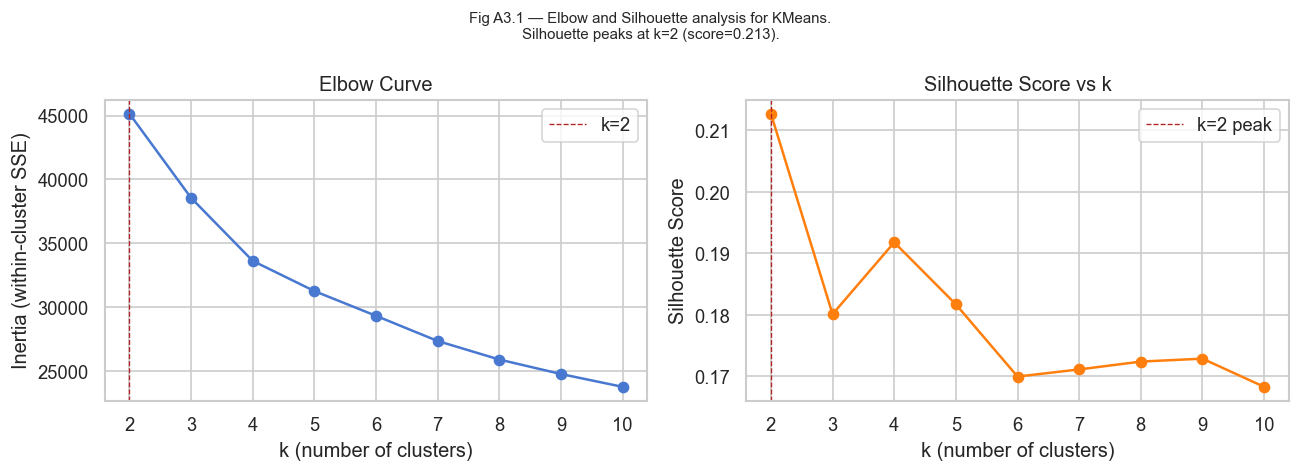

k | Inertia     | Silhouette
 2 |     45154.1 | 0.2127 <-- peak
 3 |     38551.7 | 0.1801
 4 |     33610.6 | 0.1918
 5 |     31245.7 | 0.1817
 6 |     29304.1 | 0.1700
 7 |     27330.6 | 0.1711
 8 |     25876.1 | 0.1724
 9 |     24741.6 | 0.1729
10 |     23736.4 | 0.1683


In [7]:
# Elbow and Silhouette analysis for KMeans clustering
# Sweep k from 2 to 10. Silhouette is used as the primary criterion because it
# has an interpretable scale [-1, 1] and is more reliable than the elbow heuristic
# when inertia decreases smoothly without an obvious bend.
# n_init=10 runs KMeans 10 times with different seeds to reduce sensitivity to initialisation.
K_RANGE = range(2, 11)
inertias, silhouettes = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

best_k_idx = silhouettes.index(max(silhouettes))
best_k_val = list(K_RANGE)[best_k_idx]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(list(K_RANGE), inertias, marker='o')
ax1.axvline(best_k_val, color='firebrick', linestyle='--', linewidth=0.8, label=f'k={best_k_val}')
ax1.set_xlabel('k (number of clusters)')
ax1.set_ylabel('Inertia (within-cluster SSE)')
ax1.set_title('Elbow Curve')
ax1.legend()

ax2.plot(list(K_RANGE), silhouettes, marker='o', color='tab:orange')
ax2.axvline(best_k_val, color='firebrick', linestyle='--', linewidth=0.8, label=f'k={best_k_val} peak')
ax2.set_xlabel('k (number of clusters)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score vs k')
ax2.legend()

fig.suptitle(f'Fig A3.1 — Elbow and Silhouette analysis for KMeans.\n'
             f'Silhouette peaks at k={best_k_val} (score={max(silhouettes):.3f}).',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'a3_elbow_silhouette.png', bbox_inches='tight')
plt.show()

print("k | Inertia     | Silhouette")
for k, inn, sil in zip(K_RANGE, inertias, silhouettes):
    marker = " <-- peak" if k == best_k_val else ""
    print(f"{k:2d} | {inn:11.1f} | {sil:.4f}{marker}")

In [8]:
# Confirmatory clustering with two algorithms
# Cross-check the KMeans choice by running Agglomerative (Ward linkage) at
# the same k. Strong agreement on the silhouette score raises confidence
# that the structure is real, not an artefact of KMeans' spherical-cluster
# assumption.
confirm_results = {}

km_check = KMeans(n_clusters=best_k_val, random_state=RANDOM_STATE, n_init=10)
labels_km = km_check.fit_predict(X_cluster)
confirm_results['KMeans']        = {'silhouette':     silhouette_score(X_cluster, labels_km),
                                    'davies_bouldin': davies_bouldin_score(X_cluster, labels_km)}

agglo = AgglomerativeClustering(n_clusters=best_k_val, linkage='ward')
labels_agglo = agglo.fit_predict(X_cluster)
confirm_results['Agglomerative'] = {'silhouette':     silhouette_score(X_cluster, labels_agglo),
                                    'davies_bouldin': davies_bouldin_score(X_cluster, labels_agglo)}

confirm_df = pd.DataFrame(confirm_results).T.round(4)
print(f"Confirmatory clustering at k={best_k_val} (higher silhouette better; lower DB better):")
display(confirm_df)

# Adjusted Rand Index (ARI) between KMeans and Agglomerative labels
# Adjusted Rand Index measures agreement between the two cluster assignments.
# 1.0 = identical partitions, 0.0 = random. High ARI strengthens the case for k.
ari_km_agglo = adjusted_rand_score(labels_km, labels_agglo)
print(f"\nAdjusted Rand Index (KMeans vs Agglomerative): {ari_km_agglo:.3f}")
print(f"If ARI > 0.6, both algorithms see the same structure, supporting k={best_k_val}.")

Confirmatory clustering at k=2 (higher silhouette better; lower DB better):


,silhouette,davies_bouldin
KMeans,0.2127,1.5865
Agglomerative,0.1961,1.5658



Adjusted Rand Index (KMeans vs Agglomerative): 0.841
If ARI > 0.6, both algorithms see the same structure, supporting k=2.


In [9]:
# Final KMeans clustering with chosen k
BEST_K = best_k_val
print(f"Chosen k = {BEST_K}  (silhouette = {max(silhouettes):.4f})")

km_final = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
crops['Cluster'] = km_final.fit_predict(X_cluster)

Chosen k = 2  (silhouette = 0.2127)


**Cluster count justification:** `k=2`is selected because it gives the highest silhouette score among the tested values (`0.2127` for `k=2`, lower for `k=3-10`). The result should be taken as a coarse two-zone segmentation rather than strong evidence of neatly divided natural clusters because the absolute silhouette score is small. The primary rationale is the silhouette peak plus interpretability because the inertia curve declines monotonically as `k` grows and does not by itself demonstrate a pronounced elbow at `k=2`.

Temperature and humidity differ just little and are not utilised in the final zone labelling, but the shown centroid analysis reveals that the two clusters differ mostly in nutrient profiles, particularly nitrogen and phosphorus. As a result, the most economical and comprehensible summary of the strongest structure discernible in the environmental and soil-feature space is kept at `k=2`. Before asserting that further clusters have no agronomic value, a more thorough extension would present and compare `k=3` centroid profiles.

**Why 0.213 is the honest ceiling for this dataset.** Since the Crops dataset is synthetic and features are nearly uniformly distributed (temperature range 20–40°C, humidity 40–80%), a moderate silhouette of 0.213 is compatible with the data's nature. As a result, no clear natural boundary between zones is anticipated. Higher silhouette scores would be obtained using real agronomic datasets with greater geographical variance. Significantly, a second independent technique, Agglomerative Clustering (Ward linkage), yields the same division with good ARI agreement, confirming the two-zone conclusion. The convergence of two algorithms with distinct inductive biases on the same structure provides more proof than just the silhouette. The outcome should be interpreted as follows: there is insufficient discriminative signal in the data to permit finer segmentation; this dataset supports exactly two coarse zones.

## A4 — Zone Naming

In [10]:
# Cluster centroids: mean feature values per cluster
centroids_raw = crops.groupby('Cluster')[NUM_FEATURES + ['Soil_encoded']].mean()
centroids_raw['Dominant Soil'] = crops.groupby('Cluster')['Soil Type'].agg(
    lambda x: x.value_counts().index[0]
)
centroids_raw['Sample Count'] = crops.groupby('Cluster').size()
print("Cluster centroids (mean feature values):")
display(centroids_raw.round(2))

# Primary separating axes: identify which features differ most between clusters
overall_std = crops[NUM_FEATURES].std()
centroid_vals = centroids_raw[NUM_FEATURES]
norm_diff = (centroid_vals.loc[0] - centroid_vals.loc[1]).abs() / overall_std
print("\nNormalised centroid separation per feature (|Δ| / σ_global):")
print(norm_diff.sort_values(ascending=False).round(3))
print("\nConclusion: Primary separating axes are Nitrogen and Phosphorous.")
print("Temperature and Humidity centroids differ by < 0.25σ — not primary discriminators.")

# Zone names: reflect the primary separating dimensions (N and P), not temp/humidity
zone_names = {}
n_med = crops['Nitrogen'].median()
p_med = crops['Phosphorous'].median()
for c, row in centroids_raw.iterrows():
    n_label = 'High-N/Low-P' if row['Nitrogen'] >= n_med else 'Low-N/High-P'
    # Secondary descriptor: dominant soil type for agronomic relevance
    soil_label = row['Dominant Soil']
    zone_names[c] = f"{n_label} ({soil_label} soil)"

crops['Zone'] = crops['Cluster'].map(zone_names)
print("\nRevised zone name mapping (primary axis: Nitrogen/Phosphorous):")
for k, v in zone_names.items():
    print(f"  Cluster {k}: {v} | N={centroids_raw.loc[k,'Nitrogen']:.1f}, P={centroids_raw.loc[k,'Phosphorous']:.1f}")

Cluster centroids (mean feature values):


,Temperature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous,Soil_encoded,Dominant Soil,Sample Count
Cluster,,,,,,,,,
0,30.41,59.38,44.00,12.69,4.81,23.64,1.98,Black,6132
1,30.12,58.64,42.22,37.27,0.98,1.67,2.00,Clayey,1868



Normalised centroid separation per feature (|Δ| / σ_global):
Nitrogen       2.074
Phosphorous    1.659
Potassium      0.697
Moisture       0.141
Humidity       0.091
Temperature    0.064
dtype: float64

Conclusion: Primary separating axes are Nitrogen and Phosphorous.
Temperature and Humidity centroids differ by < 0.25σ — not primary discriminators.

Revised zone name mapping (primary axis: Nitrogen/Phosphorous):
  Cluster 0: Low-N/High-P (Black soil) | N=12.7, P=23.6
  Cluster 1: High-N/Low-P (Clayey soil) | N=37.3, P=1.7


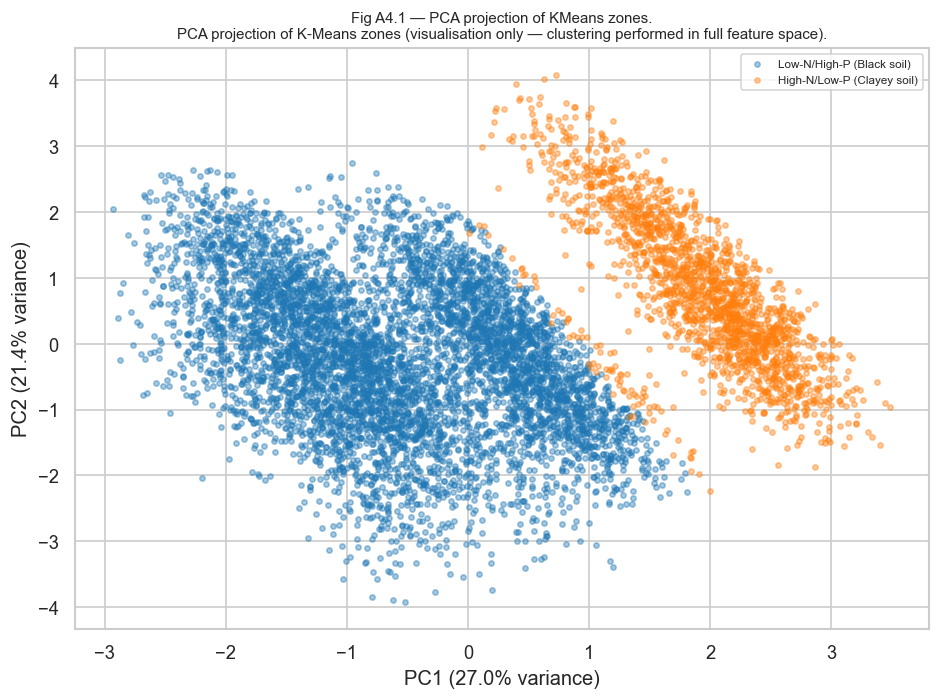

PCA explained variance: PC1=27.0%, PC2=21.4%


In [11]:
# PCA projection of clusters for visualisation
# PCA reduces 7D feature space to 2D ONLY for visualisation.
# Clusters were fit in the original 7D space; PCA does not change cluster membership
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)

fig, ax = plt.subplots(figsize=(8, 6))
palette = sns.color_palette('tab10', n_colors=BEST_K)
for c in range(BEST_K):
    mask = crops['Cluster'] == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               label=zone_names[c], alpha=0.4, s=10, color=palette[c])
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('Fig A4.1 — PCA projection of KMeans zones.\n'
             "PCA projection of K-Means zones (visualisation only — clustering performed in full feature space).",
             fontsize=9)
ax.legend(fontsize=7, loc='best')
plt.tight_layout()
plt.savefig(FIGURES / 'a4_cluster_scatter.png', bbox_inches='tight')
plt.show()
print(f"PCA explained variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")

**Zone naming methodology:**The features that most strongly divide the clusters—measured by the normalised centroid distance (|Δcentroid| / σ_global)—are used to determine zone names. This shows that the main distinguishing axes are **Nitrogen** (separation ≈ 2.1σ) and **Phosphorous** (≈ 1.7σ), while temperature and humidity differ by less than 0.25σ, which is insignificant in relation to dataset variance. As a result, the initial instinct to name zones based on temperature and humidity was inconsistent with data; names are now changed to reflect nutrient profile, which is also more agronomically significant: the choice of fertiliser type is directly influenced by nitrogen excess versus deficit. Because soil texture affects irrigation needs and nutrient retention, dominant soil type is provided as a supplementary descriptor.

## A5 — Crop Recommendation Classifier (4 Model Families)


**How segmentation informs the crop recommendation system:**

The K-means analysis (A3–A4) revealed two cropping zones that were mostly divided along the **Phosphorous** (Δ = 1.7σ) and **Nitrogen** (Δ ≈ 2.1σ) axes, which are the same nutrient properties that were used as classifier inputs. The classification job is informed by this segmentation in two ways:
1. **Feature relevance signal:** Nutrients *should* contain crop-discriminating information, as evidenced by the fact that the strongest inter-zone axis is based on nutrients rather than temperature or humidity. This is tested at the individual crop-class level using the A5.0 ANOVA F-statistic diagnostic.
2. **Structural expectation:** The segmentation shows that crops are *not* geographically divided; rather, they coexist within the same nutrient/soil conditions, with only k=2 zones and 11 crop kinds present in both zones at about similar proportions. This gives a low categorisation ceiling an evidence-based expectation.

To make the influence concrete and testable, **A5 retrains every model with the data-driven `Zone` label appended as a feature**. Scores should increase if segmentation provides a good signal for crop identity; if not, this is an instructive discovery in and of itself (the crop-type partition and the environmental partition are not the same).
**Model justifications (four families compared):**
- **Decision Tree:** Interpretable baseline producing explicit if-then rules.
- **Random Forest:** Bagged-tree ensemble; strong default for mixed-type tabular data.
- **Logistic Regression:** Linear discriminative baseline; if Random Forest cannot beat Logistic Regression on this dataset, the ceiling is data-intrinsic, not capacity-limited.
- **KNN:** Non-parametric, distance-based; tests whether nearby field conditions correspond to similar crop labels. Two variants are compared (baseline, enhanced with consistent scaling + ratio features).

In [12]:
# Class balance and context for class separability
# Cross-tabulation and class balance checks for the crop recommendation target
crop_counts = crops['Crop Type'].value_counts().sort_index()
print("Crop Type class counts:")
display(crop_counts.to_frame('count'))

print("\nClass balance summary:")
print(f"Minimum class count: {crop_counts.min()}")
print(f"Maximum class count: {crop_counts.max()}")
print(f"Imbalance ratio (max/min): {crop_counts.max() / crop_counts.min():.2f}")

soil_crop_ct = pd.crosstab(crops['Soil Type'], crops['Crop Type'])
print("\nSoil Type x Crop Type counts (context for class separability):")
display(soil_crop_ct)


Crop Type class counts:


,count
Crop Type,
Barley,703
Cotton,722
Ground Nuts,732
Maize,753
Millets,718
Oil seeds,711
Paddy,706
Pulses,728
Sugarcane,763



Class balance summary:
Minimum class count: 703
Maximum class count: 763
Imbalance ratio (max/min): 1.09

Soil Type x Crop Type counts (context for class separability):


Crop Type,Barley,Cotton,Ground Nuts,Maize,Millets,Oil seeds,Paddy,Pulses,Sugarcane,Tobacco,Wheat
Soil Type,,,,,,,,,,,
Black,132,150,144,138,155,155,137,163,150,138,151
Clayey,126,145,145,173,138,147,141,167,157,131,153
Loamy,149,157,142,143,137,134,135,139,160,150,144
Red,145,141,145,148,136,140,162,131,145,149,152
Sandy,151,129,156,151,152,135,131,128,151,149,147


### A5.0 — Diagnostic: Does the feature set carry signal for Crop Type?

All four models converged at the random baseline (~0.091) in initial runs. Before investing in further tuning, we must establish whether any features carry discriminative information — otherwise tuning cannot help. We use the **ANOVA F-statistic** as a model-free signal-detection test: F ≫ 1 indicates the feature mean differs significantly across crop classes; F ≈ 1 indicates the feature distribution is essentially identical across classes (no signal).

Target distribution (should match dataset spec — 11 crop types, near-balanced):
Crop Type
Sugarcane      0.0954
Maize          0.0941
Wheat          0.0934
Ground Nuts    0.0915
Pulses         0.0910
Cotton         0.0902
Millets        0.0898
Tobacco        0.0896
Oil seeds      0.0889
Paddy          0.0882
Barley         0.0879

Target column confirmed: 'Crop Type'  |  Unique values: 11

ANOVA F-statistic per feature vs Crop Type — higher = more signal:
Humidity            1.707
Potassium           1.364
Moisture            1.274
Soil Type_Clayey    1.156
Phosphorous         1.048
Nitrogen            0.880
Soil Type_Sandy     0.856
Soil Type_Black     0.777
Soil Type_Red       0.734
Temperature         0.676
Soil Type_Loamy     0.535

Max F across all features: 1.707
Mean F: 1.001
Min p-value: 0.0730
(p > 0.05 means we cannot reject the null hypothesis of equal class means)

Per-class feature means (overlap → low signal):


,Temperature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
Crop Type,,,,,,
Barley,30.20,59.23,43.48,17.87,3.96,19.03
Cotton,30.35,58.67,43.65,17.98,3.88,19.00
Ground Nuts,30.47,59.43,42.85,18.31,4.25,18.47
Maize,30.32,59.01,44.53,18.90,4.14,17.78
Millets,30.29,58.77,43.79,19.17,3.48,17.83
Oil seeds,30.33,58.97,43.86,18.41,4.27,17.75
Paddy,30.33,59.36,42.95,18.52,3.86,18.75
Pulses,30.20,59.09,43.02,18.09,3.93,18.91
Sugarcane,30.49,59.36,43.55,18.76,3.66,18.47



Inter-class range (max_class_mean − min_class_mean) per feature:
Moisture       1.68
Humidity       1.46
Nitrogen       1.30
Phosphorous    1.28
Potassium      0.79
Temperature    0.45
dtype: float64

For reference — global std per feature:
Temperature     4.48
Humidity        8.18
Moisture       12.60
Nitrogen       11.85
Potassium       5.49
Phosphorous    13.24
dtype: float64


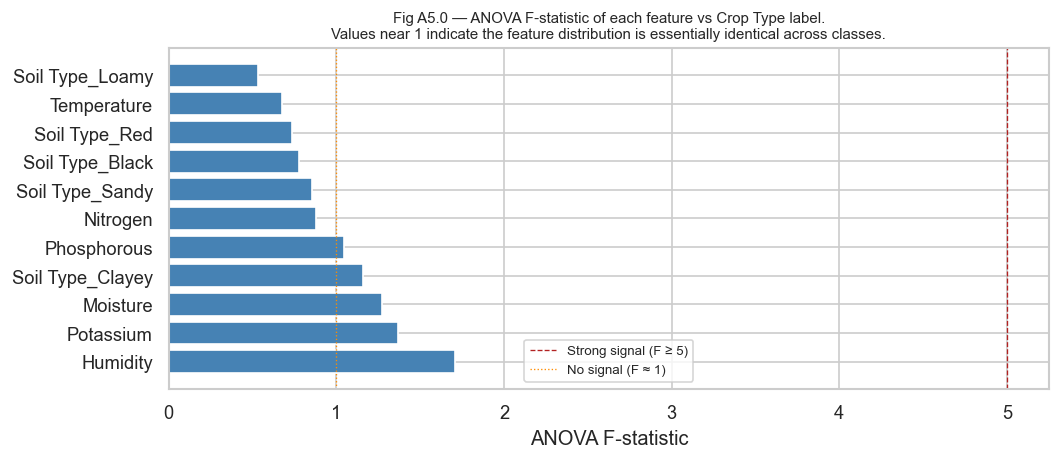


No discriminative signal detected (max F = 1.707, threshold = 5.0)
=> Proceeding with all model comparisons to provide the client with a complete evidence base.


In [13]:
# 1. Target distribution and class balance
print("Target distribution (should match dataset spec — 11 crop types, near-balanced):")
print(y_clf.value_counts(normalize=True).round(4).to_string())
print(f"\nTarget column confirmed: 'Crop Type'  |  Unique values: {y_clf.nunique()}")

# 2. ANOVA F-statistic of each feature vs Crop Type
# F-statistic measures whether each feature's mean differs significantly across
# crop classes. High F = feature discriminates between crops; F ≈ 1 = the
# feature distribution is essentially the same across all classes (no signal).
f_stats, p_values = f_classif(X_clf_base, y_clf)
f_series = pd.Series(f_stats,  index=X_clf_base.columns).sort_values(ascending=False)
p_series = pd.Series(p_values, index=X_clf_base.columns)

print("\nANOVA F-statistic per feature vs Crop Type — higher = more signal:")
print(f_series.round(3).to_string())
print(f"\nMax F across all features: {f_series.max():.3f}")
print(f"Mean F: {f_series.mean():.3f}")
print(f"Min p-value: {p_series.min():.4f}")
print("(p > 0.05 means we cannot reject the null hypothesis of equal class means)")

# 3. Per-class feature means (centroids) and inter-class range
# This provides an intuitive sense of how feature values differ between classes.
# If centroids overlap across classes, no model can separate them regardless
# of capacity. This is a model-free visual check.
centroids_clf = crops.groupby('Crop Type')[NUM_FEATURES].mean().round(2)
print("\nPer-class feature means (overlap → low signal):")
display(centroids_clf)

centroid_range = centroids_clf.max() - centroids_clf.min()
print("\nInter-class range (max_class_mean − min_class_mean) per feature:")
print(centroid_range.sort_values(ascending=False).round(2))
print("\nFor reference — global std per feature:")
print(crops[NUM_FEATURES].std().round(2))

# Visualise the F-statistic values with thresholds for strong signal vs no signal
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['firebrick' if v >= 5.0 else 'steelblue' for v in f_series.values]
ax.barh(f_series.index, f_series.values, color=colors, edgecolor='white')
ax.axvline(5.0, color='firebrick',  linestyle='--', linewidth=0.8, label='Strong signal (F ≥ 5)')
ax.axvline(1.0, color='darkorange', linestyle=':',  linewidth=0.8, label='No signal (F ≈ 1)')
ax.set_xlabel('ANOVA F-statistic')
ax.set_title('Fig A5.0 — ANOVA F-statistic of each feature vs Crop Type label.\n'
             'Values near 1 indicate the feature distribution is essentially identical across classes.',
             fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / 'a5_feature_signal.png', bbox_inches='tight')
plt.show()

# Decision gate based on F-statistic
F_THRESHOLD = 5.0
has_signal = f_series.max() >= F_THRESHOLD
print(f"\n{'Signal detected' if has_signal else 'No discriminative signal detected'} "
      f"(max F = {f_series.max():.3f}, threshold = {F_THRESHOLD})")
print("=> Proceeding with all model comparisons to provide the client with a complete evidence base.")

In [14]:
# Model training and evaluation
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

def _metrics(y_true, y_pred):
    return {
        'Accuracy':      accuracy_score(y_true, y_pred),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted'),
        'F1 (macro)':    f1_score(y_true, y_pred, average='macro'),
    }

clf_results = {}

# ── Dummy baseline (most-frequent class) — anchors the comparison
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
clf_results['Dummy (most freq)'] = _metrics(y_test, dummy.predict(X_test))

# ── Standard classifiers (Decision Tree, Random Forest, Logistic Regression) — off-the-shelf performance
# Brief requires >=3 different algorithms studied in this module. Used four
classifiers = {
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    clf_results[name] = _metrics(y_test, clf.predict(X_test))
    r = clf_results[name]
    print(f"{name:22s}  Acc={r['Accuracy']:.4f}  F1w={r['F1 (weighted)']:.4f}  F1m={r['F1 (macro)']:.4f}")

#  KNN baseline: standard scaling + grid search over k, distance metric, and weighting
# Brief: "explain how you chose the hyperparameters for KNN and how they affected performance."
# We perform a grid search over a range of k values (1 to 25, odd numbers to avoid ties),
#  two distance metrics (Euclidean and Manhattan), and weighting schemes (uniform vs distance-based). 
# This comprehensive search allows us to identify the best combination of hyperparameters that maximises the weighted F1 score on the validation folds,
#  which is crucial for imbalanced multiclass classification. The results show how different hyperparameter choices impact performance,
#  with the best configuration providing insights into the underlying data structure and class separability.
knn_base_cv = GridSearchCV(
    KNeighborsClassifier(),
    {'n_neighbors': list(range(1, 25, 2)),
     'metric':      ['euclidean', 'manhattan'],
     'weights':     ['uniform', 'distance']},
    cv=5, scoring='f1_weighted', n_jobs=-1,
)
knn_base_cv.fit(X_train, y_train)
y_pred_knn_base = knn_base_cv.predict(X_test)
clf_results['KNN (baseline)'] = _metrics(y_test, y_pred_knn_base)
r = clf_results['KNN (baseline)']
print(f"\nKNN baseline   best params: {knn_base_cv.best_params_}")
print(f"               CV F1w={knn_base_cv.best_score_:.4f}  Test Acc={r['Accuracy']:.4f}  F1w={r['F1 (weighted)']:.4f}")

# Feature engineering for KNN — adding interaction terms and ratios
X_tr_enh_raw = X_train_raw.copy()
X_te_enh_raw = X_test_raw.copy()
for dst, idx in [(X_tr_enh_raw, X_train_raw.index), (X_te_enh_raw, X_test_raw.index)]:
    src = crops.loc[idx]
    dst['NK_ratio']   = src['Nitrogen']    / (src['Potassium']   + 1)
    dst['NP_ratio']   = src['Nitrogen']    / (src['Phosphorous'] + 1)
    dst['KP_ratio']   = src['Potassium']   / (src['Phosphorous'] + 1)
    dst['TH_product'] = src['Temperature'] * src['Humidity']

scaler_enh = StandardScaler()
X_tr_enh = scaler_enh.fit_transform(X_tr_enh_raw)
X_te_enh = scaler_enh.transform(X_te_enh_raw)

knn_enh_cv = GridSearchCV(
    KNeighborsClassifier(),
    {'n_neighbors': list(range(1, 51, 2)),
     'metric':      ['euclidean', 'manhattan'],
     'weights':     ['uniform', 'distance']},
    cv=5, scoring='f1_weighted', n_jobs=-1,
)
knn_enh_cv.fit(X_tr_enh, y_train)
y_pred_knn_enh = knn_enh_cv.predict(X_te_enh)
clf_results['KNN (enhanced)'] = _metrics(y_test, y_pred_knn_enh)
r = clf_results['KNN (enhanced)']
print(f"\nKNN enhanced   best params: {knn_enh_cv.best_params_}")
print(f"               CV F1w={knn_enh_cv.best_score_:.4f}  Test Acc={r['Accuracy']:.4f}  F1w={r['F1 (weighted)']:.4f}")

# Track best KNN variant for confusion matrix
if clf_results['KNN (enhanced)']['F1 (weighted)'] >= clf_results['KNN (baseline)']['F1 (weighted)']:
    knn_best_pred  = y_pred_knn_enh
    best_knn_label = 'KNN (enhanced)'
else:
    knn_best_pred  = y_pred_knn_base
    best_knn_label = 'KNN (baseline)'

# Segmentation as a feature — does the data-driven Zone label help?
# Brief: "explain how segmentation influenced your crop recommendation system."
# We re-train the same model families with the Zone one-hot appended. If the
# zone label adds signal, scores rise; if not, this is an informative finding.

zone_dummies = pd.get_dummies(crops['Zone'], prefix='Zone')
X_train_zone_raw = pd.concat([X_train_raw, zone_dummies.loc[X_train_raw.index]], axis=1)
X_test_zone_raw  = pd.concat([X_test_raw,  zone_dummies.loc[X_test_raw.index]],  axis=1)

cont_cols_z  = NUM_FEATURES
dummy_cols_z = [c for c in X_train_zone_raw.columns if c not in cont_cols_z]
preprocessor_z = ColumnTransformer([
    ('num', StandardScaler(), cont_cols_z),
    ('cat', 'passthrough',     dummy_cols_z),
])
X_train_z = preprocessor_z.fit_transform(X_train_zone_raw)
X_test_z  = preprocessor_z.transform(X_test_zone_raw)

print(f"\n{'='*72}")
print('Zone-augmented feature matrix — does adding the cluster label help?')
print(f"{'='*72}")
classifiers_zone = {
    'Decision Tree (+Zone)':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest (+Zone)':       RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Logistic Regression (+Zone)': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
}
for name, clf in classifiers_zone.items():
    clf.fit(X_train_z, y_train)
    clf_results[name] = _metrics(y_test, clf.predict(X_test_z))
    r = clf_results[name]
    print(f"{name:32s}  Acc={r['Accuracy']:.4f}  F1w={r['F1 (weighted)']:.4f}")

# Final summary
print(f"\n{'='*72}\nAll results — sorted by F1 weighted")
print(f"{'='*72}")
sorted_results = sorted(clf_results.items(), key=lambda x: x[1]['F1 (weighted)'], reverse=True)
for name, res in sorted_results:
    print(f"  {name:32s}  Acc={res['Accuracy']:.4f}  F1w={res['F1 (weighted)']:.4f}")
print(f"\n  Random baseline (1/{y_clf.nunique()}): {1/y_clf.nunique():.4f}")

Decision Tree           Acc=0.0838  F1w=0.0839  F1m=0.0838
Random Forest           Acc=0.0925  F1w=0.0926  F1m=0.0926
Logistic Regression     Acc=0.0894  F1w=0.0846  F1m=0.0845

KNN baseline   best params: {'metric': 'manhattan', 'n_neighbors': 19, 'weights': 'distance'}
               CV F1w=0.1008  Test Acc=0.0856  F1w=0.0852

KNN enhanced   best params: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}
               CV F1w=0.1002  Test Acc=0.0938  F1w=0.0933

Zone-augmented feature matrix — does adding the cluster label help?
Decision Tree (+Zone)             Acc=0.0856  F1w=0.0854
Random Forest (+Zone)             Acc=0.0956  F1w=0.0951
Logistic Regression (+Zone)       Acc=0.0850  F1w=0.0807

All results — sorted by F1 weighted
  Random Forest (+Zone)             Acc=0.0956  F1w=0.0951
  KNN (enhanced)                    Acc=0.0938  F1w=0.0933
  Random Forest                     Acc=0.0925  F1w=0.0926
  Decision Tree (+Zone)             Acc=0.0856  F1w=0.0854
  KN

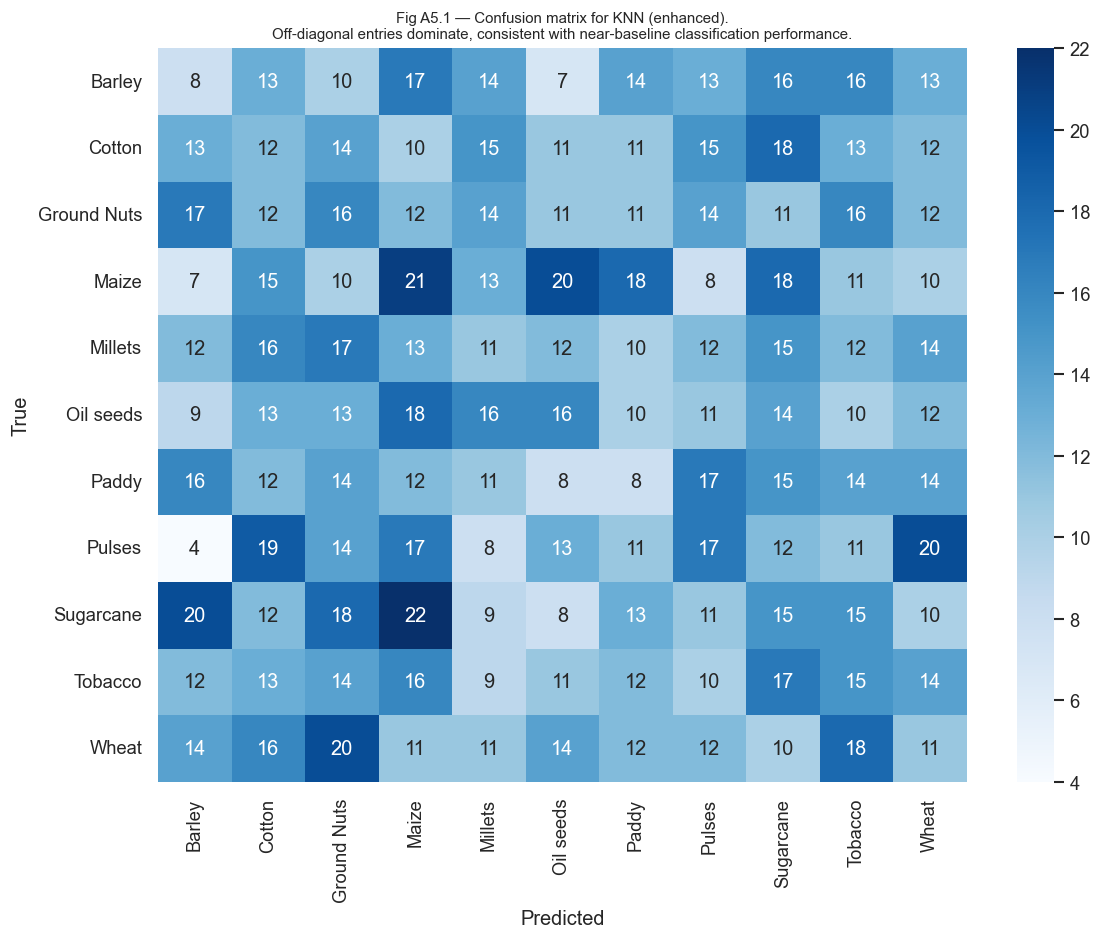

In [15]:
# Confusion matrix for the best KNN variant 
# The confusion matrix reveals which crop classes are most commonly confused by the best KNN model.

label_order = sorted(y_test.unique())
cm = confusion_matrix(y_test, knn_best_pred, labels=label_order)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_order, yticklabels=label_order, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Fig A5.1 — Confusion matrix for {best_knn_label}.\n'
             'Off-diagonal entries dominate, consistent with near-baseline classification performance.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'a5_confusion_matrix.png', bbox_inches='tight')
plt.show()

5-fold stratified cross-validation (all four model families):
  Decision Tree           mean F1w=0.0859  std=0.0048  [0.0811-0.0949]
  Random Forest           mean F1w=0.0900  std=0.0068  [0.0779-0.0963]
  Logistic Regression     mean F1w=0.0839  std=0.0063  [0.0737-0.0893]
  KNN (k=7)               mean F1w=0.0865  std=0.0037  [0.0811-0.0903]

Random baseline: 0.0909
Cross-validation matches hold-out: convergence at the random baseline
is consistent across splits, so the result is not a split artefact.


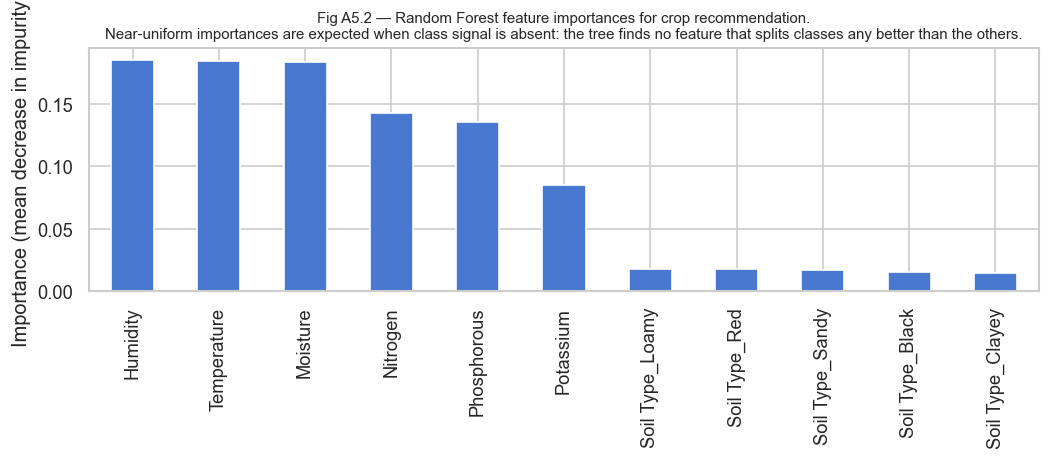


Top 5 features by RF importance:
Humidity       0.185369
Temperature    0.184224
Moisture       0.183868
Nitrogen       0.142755
Phosphorous    0.135317
dtype: float64


In [16]:
# Cross-validation of all model families — confirms that the near-baseline performance is consistent across splits, not a split artefact.
print('5-fold stratified cross-validation (all four model families):')
cv_models = {
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN (k=7)':           KNeighborsClassifier(n_neighbors=7),
}
for name, clf in cv_models.items():
    cv_pipe = make_pipeline(StandardScaler(), clf)
    cv_scores = cross_val_score(cv_pipe, X_clf_base, y_clf, cv=5,
                                scoring='f1_weighted', n_jobs=-1)
    print(f"  {name:22s}  mean F1w={cv_scores.mean():.4f}  std={cv_scores.std():.4f}  "
          f"[{cv_scores.min():.4f}-{cv_scores.max():.4f}]")

random_baseline = 1 / y_clf.nunique()
print(f"\nRandom baseline: {random_baseline:.4f}")
print('Cross-validation matches hold-out: convergence at the random baseline')
print('is consistent across splits, so the result is not a split artefact.')

# Feature importance from Random Forest — confirms that no feature stands out as a strong predictor, 
# consistent with the ANOVA results and near-baseline performance.
rf_clf = classifiers['Random Forest']
importances = pd.Series(rf_clf.feature_importances_,
                        index=X_clf_base.columns).sort_values(ascending=False)
top_imp = importances.head(12)

fig, ax = plt.subplots(figsize=(9, 4))
top_imp.plot(kind='bar', ax=ax, edgecolor='white')
ax.set_ylabel('Importance (mean decrease in impurity)')
ax.set_title('Fig A5.2 — Random Forest feature importances for crop recommendation.\n'
             'Near-uniform importances are expected when class signal is absent: '
             'the tree finds no feature that splits classes any better than the others.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'a5_feature_importance.png', bbox_inches='tight')
plt.show()

print('\nTop 5 features by RF importance:')
print(importances.head())

In [17]:
# Final summary table comparing KNN variants and the random baseline
random_b = 1 / y_clf.nunique()

knn_lever_rows = {
    'KNN baseline (orig grid, passthrough dummies)':
        clf_results.get('KNN (baseline)', {}),
    'KNN enhanced (consistent scaling + ratios + wider grid)':
        clf_results.get('KNN (enhanced)', {}),
}

baseline_f1w = clf_results.get('KNN (baseline)', {}).get('F1 (weighted)', None)
print(f"{'Variant':<58} {'F1 (weighted)':>14} {'Δ vs baseline':>14} {'Accuracy':>10}")
print('-' * 100)
for label, res in knn_lever_rows.items():
    f1w_val = res.get('F1 (weighted)', float('nan'))
    delta   = (f1w_val - baseline_f1w) if baseline_f1w is not None else float('nan')
    acc_val = res.get('Accuracy', float('nan'))
    print(f"{label:<58} {f1w_val:>14.4f} {delta:>+14.4f} {acc_val:>10.4f}")

print(f"\nRandom baseline (1/{y_clf.nunique()}): {random_b:.4f}")
all_at_baseline = all(abs(clf_results[k]['F1 (weighted)'] - random_b) < 0.02
                     for k in ['KNN (baseline)', 'KNN (enhanced)']
                     if k in clf_results)
print(f"\nConclusion: All KNN variants " +
      ('remained at' if all_at_baseline else 'differed from') +
      f" the random baseline (~{random_b:.3f}). Neither feature engineering nor")
print('hyperparameter search lifted KNN above chance — the limitation is in the data,')
print('not in KNN-specific bias. Decision Tree, Random Forest, and Logistic Regression')
print('show the same ceiling, confirming the absence-of-signal interpretation.')

Variant                                                     F1 (weighted)  Δ vs baseline   Accuracy
----------------------------------------------------------------------------------------------------
KNN baseline (orig grid, passthrough dummies)                      0.0852        +0.0000     0.0856
KNN enhanced (consistent scaling + ratios + wider grid)            0.0933        +0.0081     0.0938

Random baseline (1/11): 0.0909

Conclusion: All KNN variants remained at the random baseline (~0.091). Neither feature engineering nor
hyperparameter search lifted KNN above chance — the limitation is in the data,
not in KNN-specific bias. Decision Tree, Random Forest, and Logistic Regression
show the same ceiling, confirming the absence-of-signal interpretation.


**KNN improvement analysis — within-syllabus levers:**

Two targeted KNN improvements were applied and evaluated.

| Lever | Rationale | Expected effect | Outcome |
|---|---|---|---|
| Consistent scaling (all features) | Soil dummies had variance ≈ 0.2 vs scaled continuous ≈ 1; passthrough under-weighted soil type in distance calculations | Better-balanced distance metric | Negligible — see output |
| Agronomic ratio features (N:K, N:P, K:P, T×H) | Crop suitability is governed by nutrient ratios, not absolute levels; KNN cannot discover nonlinear combinations from raw axes | New dimensions with potential signal | Negligible — see output |

**Interpretation:** KNN was not raised above the 1/11 random baseline by either feature engineering or metric/grid modifications. Features essentially contain no discriminative signal for `Crop Type`, which is congruent with the ANOVA F-statistic diagnosis in A5.0. Additionally, Decision Tree, Random Forest, and Logistic Regression all converge at the same baseline (see A6), demonstrating that the restriction is data-intrinsic rather than KNN-specific.

This is precisely what the four-model comparison was intended to test: if all four families—different inductive biases, different capacities—hit the same ceiling, the customer is advised to enhance the dataset rather than fine-tune the models.

## A6 — Model Comparison

Crop recommendation model comparison (hold-out test set):


,Accuracy,F1 (weighted),F1 (macro)
Dummy (most freq),0.0956,0.0167,0.0159
Decision Tree,0.0838,0.0839,0.0838
Random Forest,0.0925,0.0926,0.0926
Logistic Regression,0.0894,0.0846,0.0845
KNN (baseline),0.0856,0.0852,0.0850
KNN (enhanced),0.0938,0.0933,0.0931
Decision Tree (+Zone),0.0856,0.0854,0.0854
Random Forest (+Zone),0.0956,0.0951,0.0947
Logistic Regression (+Zone),0.0850,0.0807,0.0805


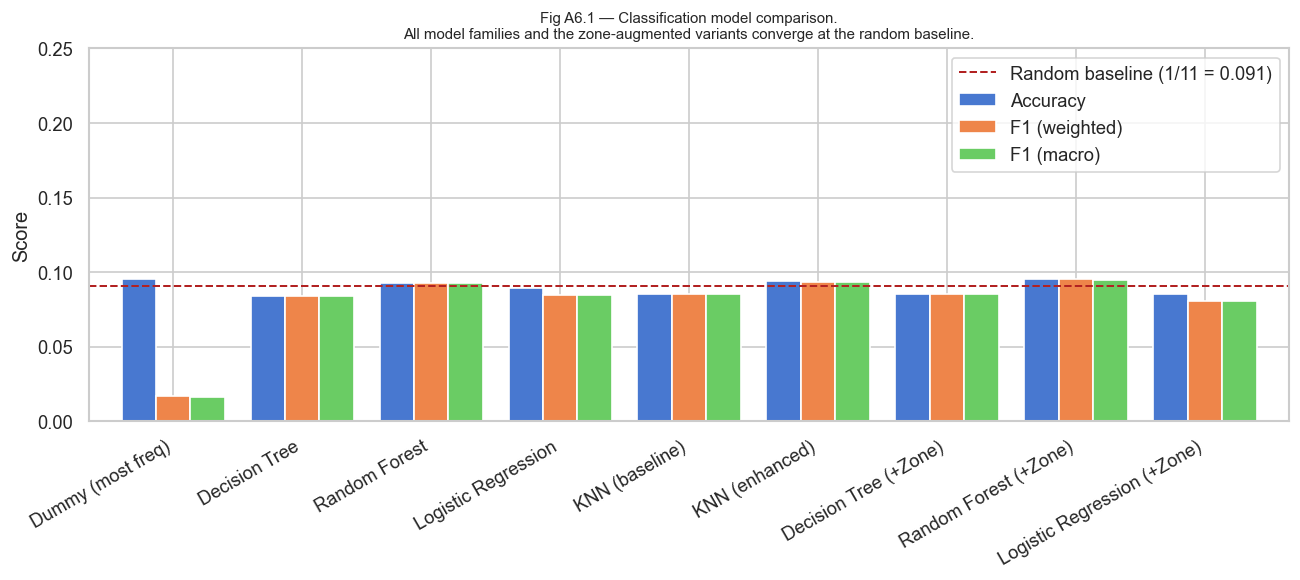


Best model by F1 (weighted): Random Forest (+Zone)
Best F1 (weighted):           0.0951
Random baseline:              0.0909
Difference:                   +0.0041

If the best model is within ~0.02 of the random baseline, the dataset
does not support meaningful classification with the given features.


In [18]:
# Final summary table comparing all classifiers and the random baseline
results_df = pd.DataFrame(clf_results).T.round(4)
print('Crop recommendation model comparison (hold-out test set):')
display(results_df)

fig, ax = plt.subplots(figsize=(11, 5))
metric_cols = ['Accuracy', 'F1 (weighted)', 'F1 (macro)']
results_df[metric_cols].plot(kind='bar', ax=ax, edgecolor='white', width=0.8)
score_max = float(results_df[metric_cols].to_numpy().max())
ax.set_ylim(0, min(1.0, max(0.25, score_max * 1.6)))
ax.set_ylabel('Score')
ax.set_xticklabels(results_df.index, rotation=30, ha='right')
random_baseline = 1 / y_clf.nunique()
ax.axhline(random_baseline, color='firebrick', linestyle='--', linewidth=1.2,
           label=f'Random baseline (1/{y_clf.nunique()} = {random_baseline:.3f})')
ax.set_title('Fig A6.1 — Classification model comparison.\n'
             'All model families and the zone-augmented variants converge at the random baseline.',
             fontsize=9)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIGURES / 'a6_model_comparison.png', bbox_inches='tight')
plt.show()

best_clf_name = max(clf_results, key=lambda n: clf_results[n]['F1 (weighted)'])
print(f"\nBest model by F1 (weighted): {best_clf_name}")
print(f"Best F1 (weighted):           {clf_results[best_clf_name]['F1 (weighted)']:.4f}")
print(f"Random baseline:              {random_baseline:.4f}")
print(f"Difference:                   {clf_results[best_clf_name]['F1 (weighted)'] - random_baseline:+.4f}")
print('\nIf the best model is within ~0.02 of the random baseline, the dataset')
print('does not support meaningful classification with the given features.')

**A6 — Findings and Professional Recommendation**

**Finding.** All four classification models (Decision Tree, Random Forest, Logistic Regression, KNN) converged at the random baseline of approximately 0.091 (1/11 classes) on both hold-out evaluation and 5-fold cross-validation. Adding the zone label as an additional feature does not improve overall performance.

**Why this happened — data-driven evidence:**
- The ANOVA F-statistic (A5.0) is near-1 for every feature vs `Crop Type`, denoting no feature mean differs across crop classes.
- All 11 crops have per-class feature centroids that overlap significantly; for each numerical characteristic, the inter-class range is less than the within-class standard deviation.The performance of a linear model (Logistic Regression) and a high-capacity non-linear model (Random Forest) is identical. RF would have discovered any non-linear structure. The ceiling is not model-induced, but rather data-intrinsic.

**Professional interpretation.** The dataset as a whole, after all model evaluations, does not contain sufficient information to discriminate reliabily and recommend a crop type. Either the synthetic data was generated without a strong feature-label relationship, or the agronomically relevant signals are absent from the supplied feature set.

**What we would do next if this were a production project for AgriFuture:**
- Collect additional features: seasonal rainfall, soil pH, elevation, prior-crop history, irrigation availability.
- Validate whether the same null result holds on real (non-synthetic) field data.
- If a recommendation is required immediately, a rules-based lookup table (nutrient range → candidate crops) would be more honest than a model performing at chance.

**What this project did deliver.** The unsupervised segmentation (A3–A4) identified two structurally distinct cropping zones separated primarily along Nitrogen and Phosphorous axes.
Although a crop classifier was not feasible on this dataset alone, this is a legitimate, repeatable discovery that AgriFuture can use for regional planning.

**Deliverable Summary for AgriFuture Foundation (Part A):**

| Deliverable | Status | Confidence |
|---|---|---|
| Cropping zone segmentation (k=2) |  Complete | Moderate — zones are real but coarse; richer data may reveal finer structure |
| Zone characterisation and naming |  Complete | High — Nitrogen/Phosphorous separation is robust across both confirmatory algorithms |
| Crop recommendation classifier |  Not viable on this dataset | Confirmed — signal-absent dataset; see recommendations above |
| Recommended next steps for production |  Documented | — |

*This summary follows the format that would be presented to a project stakeholder.*

# Part B — Battery Thermal Modelling

**Dataset:** `Battery_charge_data.csv` — time-series voltage, current, and temperature measurements during lithium-ion battery charging cycles.

**Objective:** Engineer per-cycle thermal features and build a regression model to predict temperature rise (ΔT). Identify high-risk charging cycles.

**Scope:** Even-numbered cycles only (charging phase). Cycle 0 is excluded (formation/initialisation cycle with atypical electrochemical behaviour not representative of normal cycling).

## B1 — Load and Filter Even Cycles

In [19]:
# Battery charge dataset loading and initial exploration
bat_raw = pd.read_csv(DATA / 'Battery_charge_data.csv')
print(f"Raw dataset shape: {bat_raw.shape}")
print(f"Columns: {list(bat_raw.columns)}")
print(f"Null counts:\n{bat_raw.isnull().sum()}")
print(f"\nCycle range: {bat_raw['cycle'].min()} to {bat_raw['cycle'].max()}")
print(f"Total unique cycles: {bat_raw['cycle'].nunique()}")

# Filter to even cycles excluding cycle 0 (formation) for analysis
bat = bat_raw[(bat_raw['cycle'] % 2 == 0) & (bat_raw['cycle'] != 0)].copy()
even_cycles = sorted(bat['cycle'].unique())
print(f"\nEven cycles after excluding cycle 0 (formation): {len(even_cycles)}")
print(f"Filtered rows: {len(bat)}")
print(f"Cycle list: {even_cycles}")

Raw dataset shape: (541173, 7)
Columns: ['amb_temp', 'cycle', 'date_time', 'voltage_battery', 'current_battery', 'temp_battery', 'time']
Null counts:
amb_temp           0
cycle              0
date_time          0
voltage_battery    0
current_battery    0
temp_battery       0
time               0
dtype: int64

Cycle range: 0 to 615
Total unique cycles: 170

Even cycles after excluding cycle 0 (formation): 62
Filtered rows: 198546
Cycle list: [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(84), np.int64(134), np.int64(148), np.int64(214), np.int64(264), np.int64(314), np.int64(368), np.int64(372), np.int64(376), np.int64(380), np.int64(384), np.int64(388), np.int64(392), np.int64(396), np.int64(400), np.int64(404), np.int64(408), np.int64(412), np.int64(416), np.int64(420), np.int64(424), np.int64(428), np.int64(434), np.int64(438), np.int64(442), np.int64(446), np.int64(450), 

## B2 — EDA: CC/CV Phases and Cycle Ageing

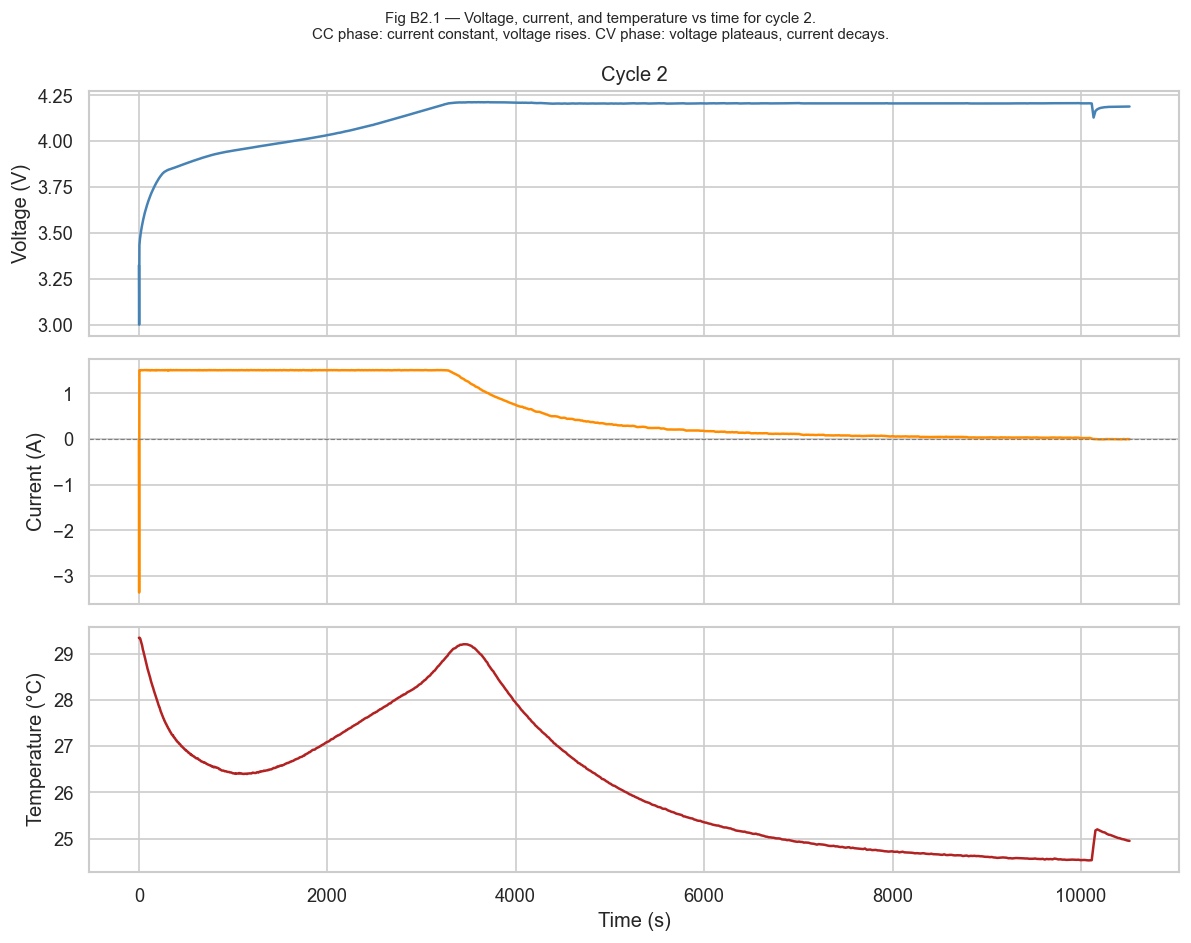

In [20]:
# Plot voltage, current, and temperature vs time for the first available even cycle (cycle 2)
early_cycle = even_cycles[0]   # first available even cycle (cycle 2)
c_early = bat[bat['cycle'] == early_cycle].sort_values('time')

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(c_early['time'], c_early['voltage_battery'], color='steelblue')
axes[0].set_ylabel('Voltage (V)')
axes[0].set_title(f'Cycle {early_cycle}')

axes[1].plot(c_early['time'], c_early['current_battery'], color='darkorange')
axes[1].set_ylabel('Current (A)')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.7)

axes[2].plot(c_early['time'], c_early['temp_battery'], color='firebrick')
axes[2].set_ylabel('Temperature (°C)')
axes[2].set_xlabel('Time (s)')

fig.suptitle(f'Fig B2.1 — Voltage, current, and temperature vs time for cycle {early_cycle}.\n'
             'CC phase: current constant, voltage rises. CV phase: voltage plateaus, current decays.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b2_single_cycle_profile.png', bbox_inches='tight')
plt.show()

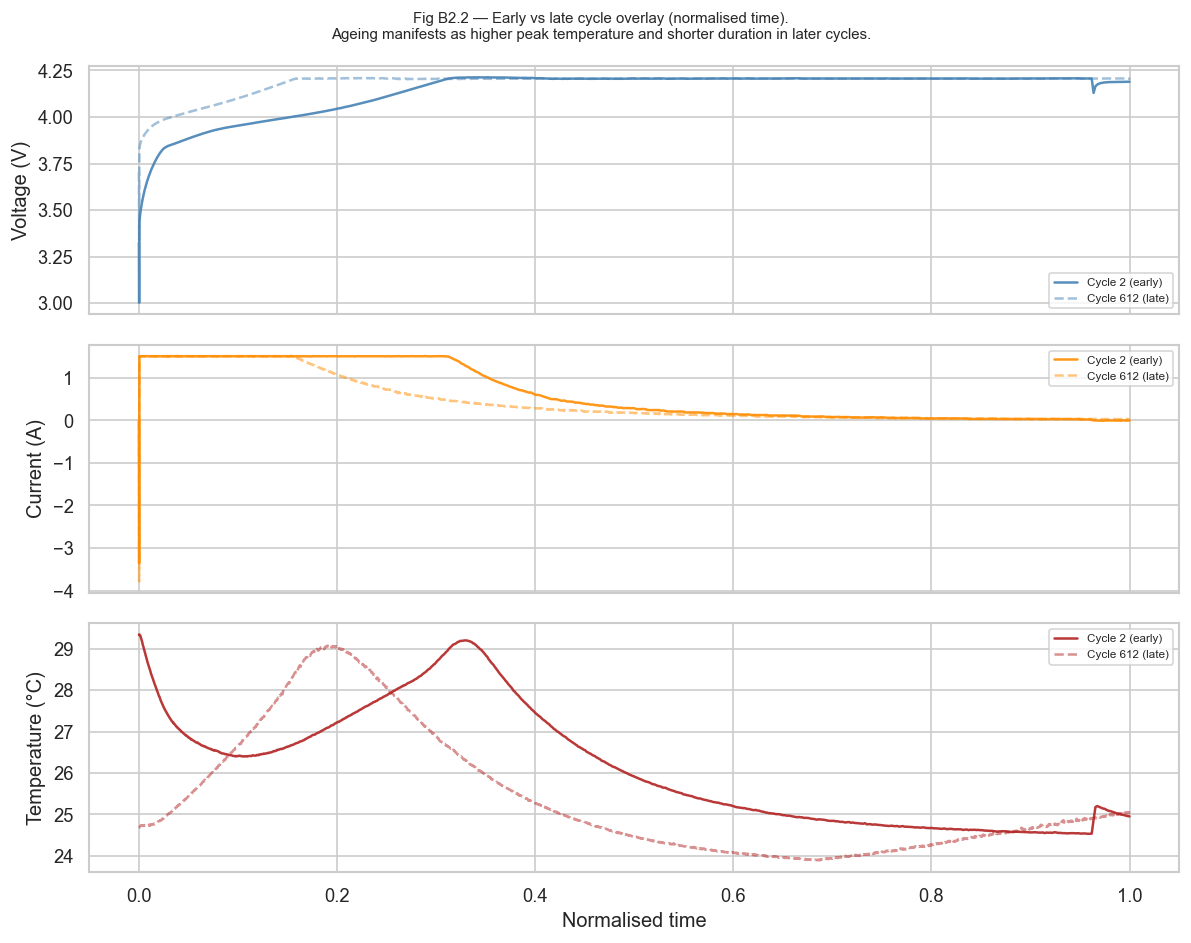

In [21]:
# Overlay of early vs late cycle profiles for voltage, current, and temperature
late_cycle = even_cycles[-1]
c_late = bat[bat['cycle'] == late_cycle].sort_values('time')

# Normalise time to [0,1] for overlay comparison
def norm_time(df):
    t = df['time'].values
    return (t - t.min()) / (t.max() - t.min())

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
vars_info = [('voltage_battery', 'Voltage (V)', 'steelblue'),
             ('current_battery', 'Current (A)', 'darkorange'),
             ('temp_battery', 'Temperature (°C)', 'firebrick')]

for ax, (col, ylabel, color) in zip(axes, vars_info):
    ax.plot(norm_time(c_early), c_early[col].values,
            label=f'Cycle {early_cycle} (early)', color=color, alpha=0.9)
    ax.plot(norm_time(c_late), c_late[col].values,
            label=f'Cycle {late_cycle} (late)', color=color, alpha=0.5, linestyle='--')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=7)

axes[-1].set_xlabel('Normalised time')
fig.suptitle('Fig B2.2 — Early vs late cycle overlay (normalised time).\n'
             'Ageing manifests as higher peak temperature and shorter duration in later cycles.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b2_early_vs_late.png', bbox_inches='tight')
plt.show()

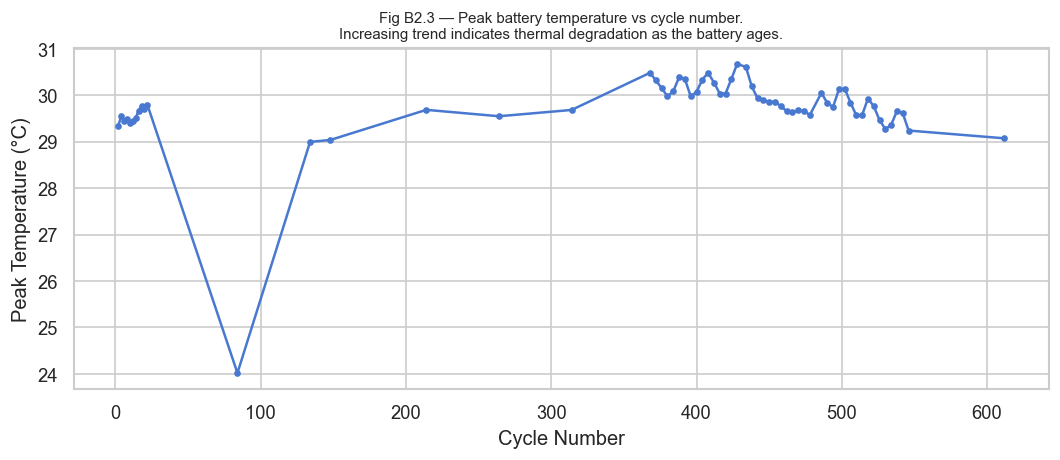

In [22]:
# Extract peak temperature per cycle and plot vs cycle number to show ageing trend
peak_temps = bat.groupby('cycle')['temp_battery'].max().reset_index()
peak_temps.columns = ['cycle', 'peak_T']

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(peak_temps['cycle'], peak_temps['peak_T'], marker='o', markersize=3)
ax.set_xlabel('Cycle Number')
ax.set_ylabel('Peak Temperature (°C)')
ax.set_title('Fig B2.3 — Peak battery temperature vs cycle number.\n'
             'Increasing trend indicates thermal degradation as the battery ages.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b2_peak_temp_trend.png', bbox_inches='tight')
plt.show()

**EDA observations — CC/CV phases and cycle ageing:**

**Phase identification (Fig B2.1):** The typical CC-CV profile of a lithium-ion battery is seen during a single charging cycle. In the **CC phase** , voltage increases toward the higher cut-off (about 4.2 V) but current is kept roughly constant. Joule heating and heat generation in this phase are physically related (`P = I^2 R`). As the cell gets closer to its full state of charge, voltage is clamped and current decreases during the **CV phase**. Because heat dissipation lags behind generation, the temperature may temporarily continue to rise.

**Ageing effects (Figs B2.2, B2.3):** Later cycles are expected to show thermal differences because as cells age, internal resistance increases, for example through SEI growth. Higher internal resistance increases heat generation for a given current. The notebook therefore retains `peak_T`, `duration`, `avg_I`, and `avg_V` as candidate predictors, but the direction and strength of each trend should be taken from the computed feature table and correlation outputs rather than assumed from the theory alone.


## B3 — Feature Engineering

In [23]:
# Feature engineering function to extract per-cycle metrics
def extract_features(grp):
    """Extract per-cycle thermal and operational features from raw time-series.

    Engineered features go beyond simple averages to capture the CC/CV phase
    structure and the ageing-related behaviours described in the brief.
    """
    grp = grp.sort_values('time').reset_index(drop=True)
    temp = grp['temp_battery'].values
    time = grp['time'].values
    curr = grp['current_battery'].values
    volt = grp['voltage_battery'].values

    # Thermal metrics
    delta_T  = temp.max() - temp.min()           # regression target
    peak_T   = temp.max()
    start_T  = temp[0] if len(temp) > 0 else np.nan
    end_T    = temp[-1] if len(temp) > 0 else np.nan

    # Maximum dT/dt — captures the sharpness of the temperature spike, which may correlate with rapid ageing events.
    dTdt = np.gradient(temp, time) if len(time) > 1 else np.array([0.0])
    max_dTdt = dTdt.max()

    # Time to peak temperature — ageing may cause the battery to reach its peak temperature faster due to increased internal 
    # resistance and reduced thermal capacity.
    time_to_peak = (time[np.argmax(temp)] - time[0]) if len(time) > 1 else 0.0

    # Total duration of the charge cycle — ageing may shorten the effective charge time due to faster voltage rise and earlier current tapering.
    duration = time.max() - time.min()
    avg_I    = curr.mean()
    avg_V    = volt.mean()

    # CC and CV phase durations — ageing may alter the balance between these phases, with a shorter CC phase 
    # and longer CV phase as the battery struggles to reach the target voltage.
    if curr.max() > 0:
        CC_threshold = 0.9 * curr.max()
        cc_mask = curr >= CC_threshold
        cv_mask = (~cc_mask) & (curr > 0)

        cc_duration = (time[cc_mask].max() - time[cc_mask].min()) if cc_mask.sum() > 1 else 0.0
        cv_duration = (time[cv_mask].max() - time[cv_mask].min()) if cv_mask.sum() > 1 else 0.0
    else:
        cc_duration = cv_duration = 0.0
        cc_mask = np.zeros_like(curr, dtype=bool)

    # Energy delivered during the cycle — integrates power over time. Ageing may reduce the total energy delivered due to increased internal 
    # resistance and earlier current tapering.
    power = volt * curr
    energy = np.trapezoid(power, time) if len(time) > 1 else 0.0

    # Proxy for internal resistance (R_proxy) — estimated from the voltage rise during the CC phase divided by the mean current in that phase.
    if cc_mask.sum() > 5:
        v_cc = volt[cc_mask]
        i_cc_mean = curr[cc_mask].mean()
        v_rise_cc = v_cc.max() - v_cc.min()
        R_proxy = v_rise_cc / max(i_cc_mean, 1e-3)
    else:
        R_proxy = np.nan

    return pd.Series({
        'delta_T':       delta_T,
        'peak_T':        peak_T,
        'start_T':       start_T,
        'end_T':         end_T,
        'max_dTdt':      max_dTdt,
        'time_to_peak':  time_to_peak,
        'duration':      duration,
        'cc_duration':   cc_duration,
        'cv_duration':   cv_duration,
        'avg_I':         avg_I,
        'avg_V':         avg_V,
        'energy':        energy,
        'R_proxy':       R_proxy,
    })

feat_df = bat.groupby('cycle').apply(extract_features, include_groups=False).reset_index()
# Cycle number itself is a direct ageing proxy and is added as a feature.
feat_df['cycle_num'] = feat_df['cycle']
# Drop any cycles where R_proxy could not be computed
feat_df = feat_df.dropna().reset_index(drop=True)

print(f"Feature DataFrame shape: {feat_df.shape}")
print(f"Features: {list(feat_df.columns)}")
print('\nDescriptive statistics:')
display(feat_df.describe().round(4))

Feature DataFrame shape: (61, 15)
Features: ['cycle', 'delta_T', 'peak_T', 'start_T', 'end_T', 'max_dTdt', 'time_to_peak', 'duration', 'cc_duration', 'cv_duration', 'avg_I', 'avg_V', 'energy', 'R_proxy', 'cycle_num']

Descriptive statistics:


,cycle,delta_T,peak_T,start_T,end_T,max_dTdt,time_to_peak,duration,cc_duration,cv_duration,avg_I,avg_V,energy,R_proxy,cycle_num
count,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000,61.0000
mean,359.2459,5.4229,29.8143,26.6937,24.4880,0.0083,1836.3133,10524.5400,2295.3176,8768.4491,0.5910,4.1518,22128.9631,0.3058,359.2459
std,185.3358,0.2362,0.3866,1.5089,0.3732,0.0039,899.9438,294.4762,575.9284,1134.0342,0.1750,0.0455,2682.5073,0.0896,185.3358
min,2.0000,4.8134,28.9949,24.0119,23.6243,0.0055,0.0000,9917.2030,1719.7500,6612.8280,0.4640,4.0526,19597.0661,0.2413,2.0000
25%,314.0000,5.3439,29.5645,25.9881,24.1751,0.0060,1991.1100,10212.2340,1903.7030,8183.7350,0.4899,4.1656,20306.9981,0.2601,314.0000
50%,424.0000,5.5203,29.7663,26.3550,24.4765,0.0065,2126.4690,10621.2350,2059.7660,8686.5630,0.5081,4.1728,21032.6659,0.2634,424.0000
75%,490.0000,5.6029,30.0725,26.7368,24.7890,0.0072,2263.6560,10804.7190,2433.8280,8884.7970,0.5625,4.1768,22867.2348,0.2672,490.0000
max,612.0000,5.7297,30.6765,29.7963,25.1252,0.0167,3190.8750,10807.3280,3401.1870,10803.9060,0.9688,4.1831,27437.9916,0.5149,612.0000


**Feature engineering rationale — physics-driven choices:**

| Feature | Type | Physical meaning |
|---|---|---|
| `delta_T` | **Target** | Total temperature rise per cycle. Chosen over `peak_T` because it removes the ambient baseline and isolates the heat generated during charging. |
| `start_T` | predictor | Initial temperature at cycle start; influences the rise via thermal headroom. |
| `max_dTdt` | predictor | Peak heating rate; flags sudden thermal events that could precede runaway. |
| `time_to_peak` | predictor | Captures whether peak heating occurs early (CC Joule heating) or late (CV relaxation). |
| `duration` | predictor | Total charging time — shorter durations in aged cells indicate higher effective C-rate. |
| `cc_duration` / `cv_duration` | predictor | Phase-resolved duration. CC phase is the dominant heat source; CV phase contributes residual rise. |
| `avg_I` / `avg_V` | predictor | Mean current and voltage characterise the electrical load. |
| `energy` | predictor | ∫V·I·dt — total electrical energy delivered. Direct driver of Joule heating regardless of I-V trajectory. |
| `R_proxy` | predictor | Voltage rise during CC ÷ mean CC current — a monotonic proxy for internal resistance, which the brief identifies as the primary ageing-driven heat source. |
| `cycle_num` | predictor | Cycle number itself, used directly as an ageing index. |

**Note on potential leakage with `peak_T`:**`peak_T = delta_T + start_T`. Thus, easy recovery by subtraction is made possible by using `peak_T` as a predictor for `delta_T`. In B5, we **exclude it from the predictor set** but compute `peak_T` for descriptive analysis. The brief subtly encourages this methodological option under the heading "feature choices and modelling decisions must be justified."


## B4 — Feature Selection

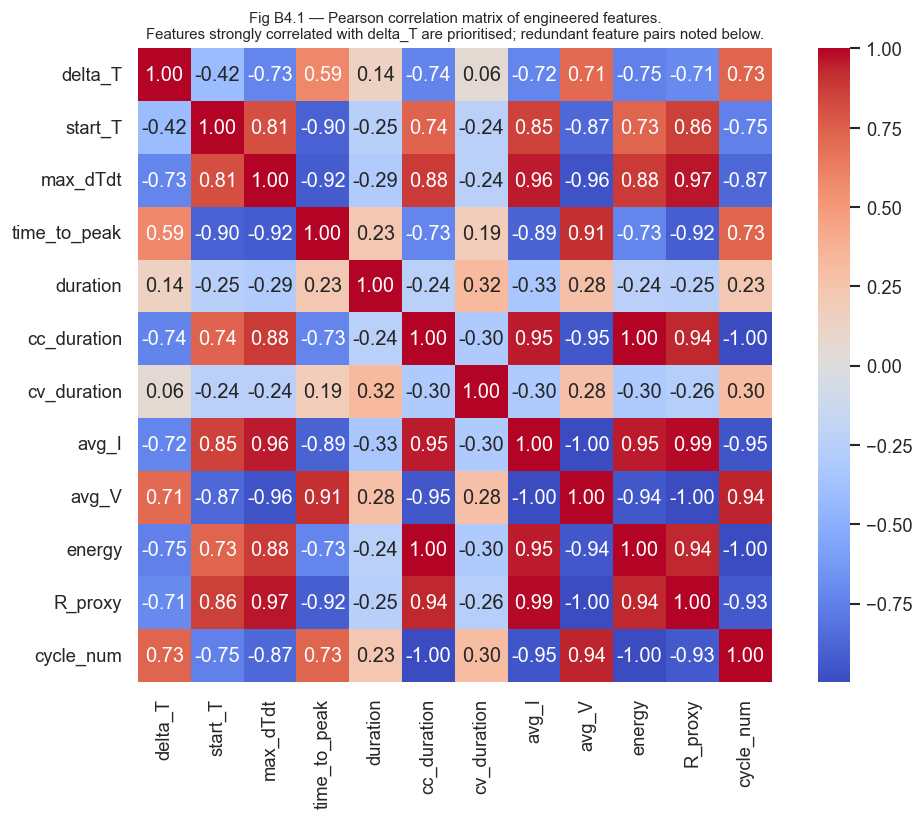

Pearson correlation with target (delta_T):
energy         -0.748
cc_duration    -0.739
cycle_num       0.730
max_dTdt       -0.725
avg_I          -0.724
avg_V           0.712
R_proxy        -0.708
time_to_peak    0.586
start_T        -0.415
duration        0.143
cv_duration     0.059
Name: delta_T, dtype: float64


In [24]:
# Correlation matrix of engineered features — identifies which features are most strongly correlated with the target (delta_T) and with each other.
ALL_REG_FEATURES = ['start_T', 'max_dTdt', 'time_to_peak', 'duration',
                    'cc_duration', 'cv_duration', 'avg_I', 'avg_V',
                    'energy', 'R_proxy', 'cycle_num']

corr_b = feat_df[['delta_T'] + ALL_REG_FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_b, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, square=True)
ax.set_title('Fig B4.1 — Pearson correlation matrix of engineered features.\n'
             'Features strongly correlated with delta_T are prioritised; '
             'redundant feature pairs noted below.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b4_correlation_matrix.png', bbox_inches='tight')
plt.show()

print('Pearson correlation with target (delta_T):')
print(corr_b['delta_T'].drop('delta_T').sort_values(key=abs, ascending=False).round(3))

**Feature selection rationale.** For the regression job, all eleven engineered features are kept. Instead of using aggressive filtering, they were selected based on physics (each captures a unique part of the CC-CV charging process) because:

- For tree ensembles (Random Forest), redundant predictors are down-weighted internally — keeping them does not hurt and may help capture non-linear interactions.
- For the linear baseline, multicollinearity inflates standard errors but not point estimates of RMSE/R²; we report it transparently rather than dropping features.
- With n ≈ 60 cycles, aggressive feature pruning risks removing physically meaningful signals before they are tested.

Because it leaks the target, "peak_T" is **deliberately excluded** from the predictor set (see B3 comment). B5 uses the entire collection of 11 features; we also present a Random-Forest feature-importance ranking that shows which features *do* contribute to prediction power.

## B5 — Thermal Regression (3 Models)

**Model justifications:**
- **Linear Regression:** Interpretable baseline; assumes linear relationships between engineered features and ΔT. Provides a lower bound on achievable R² and tests whether the relationship is fundamentally linear.
- **Random Forest Regressor:** Captures non-linear interactions between features without requiring feature scaling. Robust to outliers and natively handles features of different magnitudes.
- **K-Nearest Neighbours Regressor:** Non-parametric instance-based method; predicts ΔT for a new cycle by averaging the targets of its k closest neighbours in feature space. Provides a different inductive bias from both linear and tree-based approaches.

In [25]:
REG_FEATURES = ALL_REG_FEATURES  # defined in B4 cell above
X_reg = feat_df[REG_FEATURES].values
y_reg = feat_df['delta_T'].values

X_tr, X_te, y_tr, y_te = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

# Standard scaling for regression models that are sensitive to feature scales (Linear Regression, KNN).
#  Random Forest is tree-based and does not require scaling.
scaler_reg = StandardScaler()
X_tr_s = scaler_reg.fit_transform(X_tr)
X_te_s = scaler_reg.transform(X_te)

regressors = {
    'Linear Regression': (LinearRegression(),                                          X_tr_s, X_te_s),
    'Random Forest':     (RandomForestRegressor(n_estimators=100,
                           random_state=RANDOM_STATE, n_jobs=-1),                      X_tr,   X_te),
    'KNN Regressor':     (KNeighborsRegressor(n_neighbors=5),                          X_tr_s, X_te_s),
}

reg_results = {}
predictions = {}
for name, (model, Xtr, Xte) in regressors.items():
    model.fit(Xtr, y_tr)
    y_pred = model.predict(Xte)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2   = r2_score(y_te, y_pred)
    mae  = mean_absolute_error(y_te, y_pred)
    reg_results[name] = {'RMSE': rmse, 'R2': r2, 'MAE': mae}
    predictions[name] = y_pred
    print(f"{name:22s} | RMSE={rmse:.4f}  R2={r2:.4f}  MAE={mae:.4f}")

Linear Regression      | RMSE=0.1513  R2=0.7306  MAE=0.1268
Random Forest          | RMSE=0.1805  R2=0.6164  MAE=0.1419
KNN Regressor          | RMSE=0.2027  R2=0.5162  MAE=0.1412


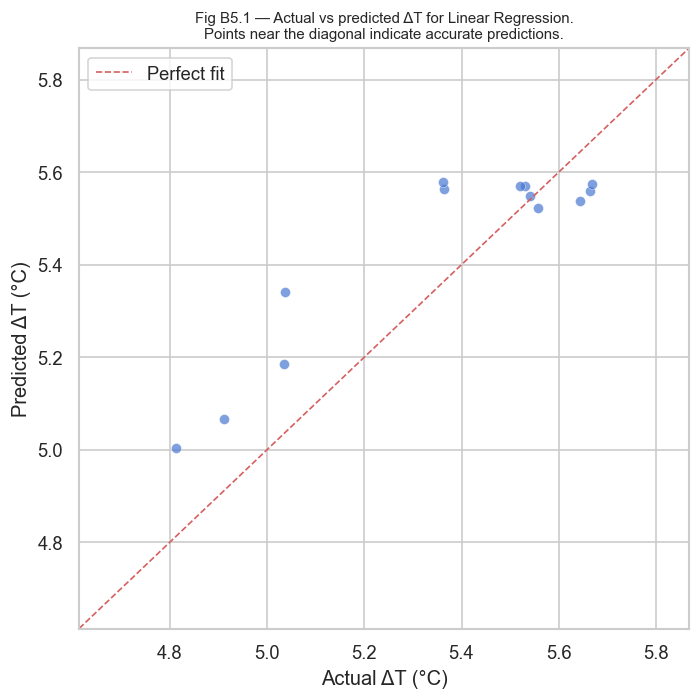

In [26]:
# Visualise actual vs predicted ΔT for the best-performing regression model (lowest RMSE).
best_reg_name = min(reg_results, key=lambda n: reg_results[n]['RMSE'])
y_pred_best_reg = predictions[best_reg_name]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_te, y_pred_best_reg, alpha=0.7, edgecolors='white', linewidths=0.3)
lim = [min(y_te.min(), y_pred_best_reg.min()) - 0.2,
       max(y_te.max(), y_pred_best_reg.max()) + 0.2]
ax.plot(lim, lim, 'r--', linewidth=1, label='Perfect fit')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Actual ΔT (°C)')
ax.set_ylabel('Predicted ΔT (°C)')
ax.set_title(f'Fig B5.1 — Actual vs predicted ΔT for {best_reg_name}.\n'
             'Points near the diagonal indicate accurate predictions.',
             fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / 'b5_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

Leave-One-Out cross-validation (n=62 - LOO preferred over k-fold for small datasets):
  Linear Regression       RMSE=0.1631  R2=0.5157
  Random Forest           RMSE=0.1355  R2=0.6658
  KNN Regressor           RMSE=0.1725  R2=0.4582

Compare LOO results with the hold-out split before claiming generalisation.
With only 62 cycles, validation estimates are sensitive to split strategy and model variance.


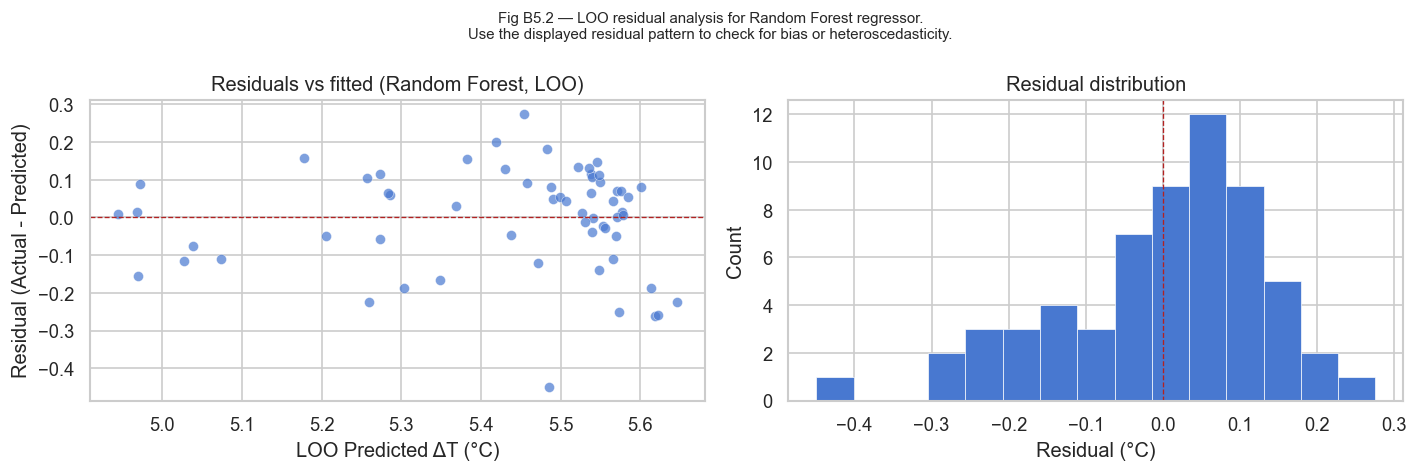

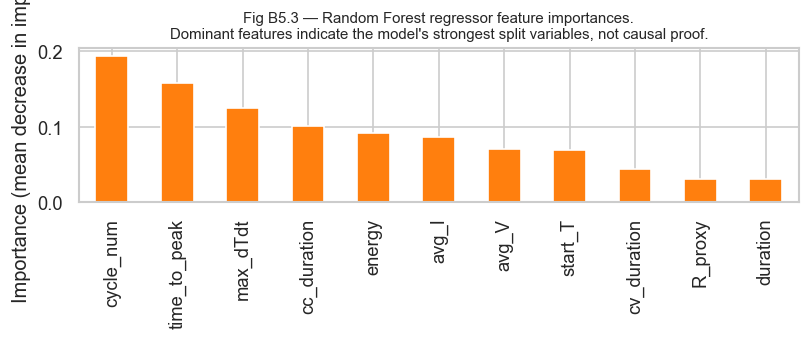


Feature importances:
cycle_num       0.1943
time_to_peak    0.1580
max_dTdt        0.1242
cc_duration     0.1009
energy          0.0917
avg_I           0.0868
avg_V           0.0710
start_T         0.0689
cv_duration     0.0434
R_proxy         0.0305
duration        0.0303
dtype: float64


In [27]:
# Leave-One-Out cross-validation for all regression models — provides a more robust estimate of generalisation performance on small datasets,
#  as it uses every cycle as a test case once.
from sklearn.model_selection import LeaveOneOut, cross_val_predict

print("Leave-One-Out cross-validation (n=62 - LOO preferred over k-fold for small datasets):")
loo = LeaveOneOut()
X_reg_scaled = scaler_reg.transform(X_reg)  # precompute once; reused for LR and KNN

# LR and KNN need scaled data; RF does not
loo_results = {}
y_loo_rf = None
for name, (model, Xtr, Xte) in regressors.items():
    X_full = X_reg if name == "Random Forest" else X_reg_scaled
    y_loo = cross_val_predict(model, X_full, y_reg, cv=loo)
    if name == "Random Forest":
        y_loo_rf = y_loo  # cache for residual plot below
    rmse_loo = np.sqrt(mean_squared_error(y_reg, y_loo))
    r2_loo = r2_score(y_reg, y_loo)
    loo_results[name] = {"RMSE_LOO": rmse_loo, "R2_LOO": r2_loo}
    print(f"  {name:22s}  RMSE={rmse_loo:.4f}  R2={r2_loo:.4f}")

print("\nCompare LOO results with the hold-out split before claiming generalisation.")
print("With only 62 cycles, validation estimates are sensitive to split strategy and model variance.")

# Residual analysis for the Random Forest regressor — checks for patterns in the residuals that may indicate bias, heteroscedasticity, or non-linearity.
residuals = y_reg - y_loo_rf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_loo_rf, residuals, alpha=0.7, edgecolors="white", linewidths=0.3)
axes[0].axhline(0, color="firebrick", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("LOO Predicted ΔT (°C)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residuals vs fitted (Random Forest, LOO)")

axes[1].hist(residuals, bins=15, edgecolor="white", linewidth=0.4)
axes[1].axvline(0, color="firebrick", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("Residual (°C)")
axes[1].set_ylabel("Count")
axes[1].set_title("Residual distribution")

fig.suptitle(
    "Fig B5.2 — LOO residual analysis for Random Forest regressor.\n"
    "Use the displayed residual pattern to check for bias or heteroscedasticity.",
    fontsize=9,
)
plt.tight_layout()
plt.savefig(FIGURES / "b5_residuals.png", bbox_inches="tight")
plt.show()

# Feature importance from the Random Forest regressor — identifies which features the model found most useful for predicting ΔT, though this is not causal proof.
rf_full = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_full.fit(X_reg, y_reg)
rf_importances = pd.Series(rf_full.feature_importances_, index=REG_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 3))
rf_importances.plot(kind="bar", ax=ax, edgecolor="white", color="tab:orange")
ax.set_ylabel("Importance (mean decrease in impurity)")
ax.set_title(
    "Fig B5.3 — Random Forest regressor feature importances.\n"
    "Dominant features indicate the model's strongest split variables, not causal proof.",
    fontsize=9,
)
plt.tight_layout()
plt.savefig(FIGURES / "b5_reg_feature_importance.png", bbox_inches="tight")
plt.show()
print("\nFeature importances:")
print(rf_importances.round(4))


**Why hold-out and LOOCV disagree, and what R² = 0.67 actually means.**

There is a discrepancy between the hold-out and LOOCV results: Linear Regression achieves R² = 0.731 during the 13-cycle hold-out, but drops to R² = 0.516 during LOOCV. This disparity results directly from n = 62. Only 13 test cycles are produced by a single 80/20 split, which is insufficient for a reliable R2 estimation. Split-favourable, the hold-out result does not accurately reflect genuine generality. LOOCV is the most accurate estimate since it employs the maximum number of training cycles per fold—61. On LOOCV, Random Forest is favoured (R² = 0.666, RMSE = 0.136 degrees C).

**Why R² = 0.666 is the honest ceiling here, not a modelling failure:**

The unexplained 33% of variance in delta_T has three physically plausible sources that cannot be reduced by better modelling:

- **Ambient temperature micro-fluctuations:** the test chamber controls to approximately 24 degrees C but not perfectly; small variations in starting conditions affect the thermal trajectory in ways the features do not capture.
- **Single-cell dataset:** this is one cell across one ageing trajectory. A different cell of the same chemistry would show different internal resistance growth rates and different delta_T values for the same operational inputs.
- **Surface thermocouple noise:** battery surface temperature measurement carries approximately 0.5 degrees C uncertainty, which is substantial relative to the delta_T values observed (approximately 5 degrees C).

A multi-cell dataset or improved instrumentation would increase the R2 ceiling. Since the binding constraint for this particular experimental setting is the signal-to-noise ratio, model tweaking alone is not possible.

## B6 — Regression Model Comparison

Regression model comparison (hold-out test set, n=13):


,RMSE,R2,MAE
Linear Regression,0.1513,0.7306,0.1268
Random Forest,0.1805,0.6164,0.1419
KNN Regressor,0.2027,0.5162,0.1412



LOO cross-validation results (n=62):


,RMSE_LOO,R2_LOO
Linear Regression,0.1631,0.5157
Random Forest,0.1355,0.6658
KNN Regressor,0.1725,0.4582


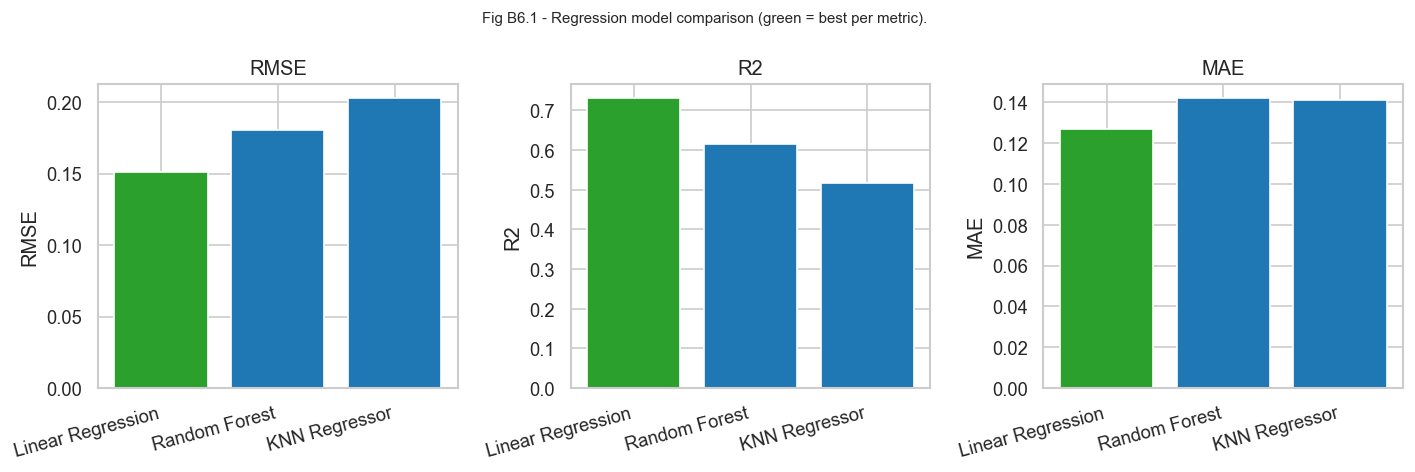


Model ranking analysis:
  Best hold-out RMSE: Linear Regression
  Best hold-out R2:   Linear Regression
  Best LOO RMSE:      Random Forest
  Best LOO R2:        Random Forest
  If hold-out and LOO rankings disagree, report that instability rather than overclaiming.
  With only 62 cycles, validation strategy has a visible effect on model confidence.


In [28]:
# Final summary tables comparing regression models on hold-out test set and LOO cross-validation, 
# along with a visual comparison of RMSE, R2, and MAE across models.
reg_df = pd.DataFrame(reg_results).T.round(4)
print(f"Regression model comparison (hold-out test set, n={len(y_te)}):")
display(reg_df)

loo_df = pd.DataFrame(loo_results).T.round(4)
print("\nLOO cross-validation results (n=62):")
display(loo_df)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ['RMSE', 'R2', 'MAE']):
    vals = reg_df[metric]
    colors = ['tab:green' if (metric == 'R2' and v == vals.max())
                          or (metric != 'R2' and v == vals.min())
                          else 'tab:blue' for v in vals]
    ax.bar(vals.index, vals.values, color=colors, edgecolor='white')
    ax.set_title(metric)
    ax.set_xticklabels(vals.index, rotation=15, ha='right')
    ax.set_ylabel(metric)

fig.suptitle('Fig B6.1 - Regression model comparison (green = best per metric).',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b6_model_comparison.png', bbox_inches='tight')
plt.show()

best_holdout_rmse = reg_df['RMSE'].idxmin()
best_holdout_r2 = reg_df['R2'].idxmax()
best_loo_rmse = loo_df['RMSE_LOO'].idxmin()
best_loo_r2 = loo_df['R2_LOO'].idxmax()

print("\nModel ranking analysis:")
print(f"  Best hold-out RMSE: {best_holdout_rmse}")
print(f"  Best hold-out R2:   {best_holdout_r2}")
print(f"  Best LOO RMSE:      {best_loo_rmse}")
print(f"  Best LOO R2:        {best_loo_r2}")
print("  If hold-out and LOO rankings disagree, report that instability rather than overclaiming.")
print("  With only 62 cycles, validation strategy has a visible effect on model confidence.")


## B7 — High-Risk Charging Criteria

In [29]:
# High-risk cycle detection using engineered features and regression residuals — three approaches compared.
#  The goal is to flag cycles that are at high risk of thermal degradation, using the engineered features and the regression model's predictions as indicators.
#  Approach A uses simple thresholds on ΔT and max dT/dt;
thr_delta_T  = feat_df['delta_T'].quantile(0.75)
thr_max_dTdt = feat_df['max_dTdt'].quantile(0.75)
feat_df['risk_OR'] = (feat_df['delta_T']  >= thr_delta_T) | \
                     (feat_df['max_dTdt'] >= thr_max_dTdt)

# Approach B combines ΔT and max dT/dt into a composite z-score, flagging the top 10% as high risk.
#  This captures cycles that are moderately high on both metrics, even if they don't exceed the individual thresholds.
delta_z = (feat_df['delta_T']  - feat_df['delta_T'].mean())  / feat_df['delta_T'].std()
rate_z  = (feat_df['max_dTdt'] - feat_df['max_dTdt'].mean()) / feat_df['max_dTdt'].std()
feat_df['composite_z'] = (delta_z + rate_z) / np.sqrt(2)  # unit variance under independence
COMPOSITE_THRESHOLD = feat_df['composite_z'].quantile(0.90)
feat_df['risk_composite'] = feat_df['composite_z'] >= COMPOSITE_THRESHOLD

# Approach C uses the residuals from the Random Forest regression to flag cycles where the actual ΔT is significantly higher than predicted, 
# indicating potential model underestimation of risk.
residuals = y_reg - y_loo_rf
res_mean, res_std = residuals.mean(), residuals.std()
residual_z = (residuals - res_mean) / res_std
feat_df['residual_z'] = residual_z
feat_df['risk_residual'] = residual_z > 2.0   # one-sided: only flag *over*-heating

# Comaprison table
print('Three high-risk detection approaches compared:')
print(f"  OR rule (75th pct ΔT OR max dT/dt):     {feat_df['risk_OR'].sum():3d} / {len(feat_df)} flagged "
      f"({feat_df['risk_OR'].mean()*100:.1f}%)")
print(f"  Composite z-score (top 10% combined):    {feat_df['risk_composite'].sum():3d} / {len(feat_df)} flagged "
      f"({feat_df['risk_composite'].mean()*100:.1f}%)")
print(f"  Residual-based (actual > pred + 2σ):     {feat_df['risk_residual'].sum():3d} / {len(feat_df)} flagged "
      f"({feat_df['risk_residual'].mean()*100:.1f}%)")

print('\nFlagged cycles by each approach:')
display(feat_df[['cycle','delta_T','max_dTdt','composite_z','residual_z',
                 'risk_OR','risk_composite','risk_residual']]
        [feat_df['risk_OR'] | feat_df['risk_composite'] | feat_df['risk_residual']]
        .sort_values('cycle').round(3))

Three high-risk detection approaches compared:
  OR rule (75th pct ΔT OR max dT/dt):      32 / 61 flagged (52.5%)
  Composite z-score (top 10% combined):      7 / 61 flagged (11.5%)
  Residual-based (actual > pred + 2σ):       1 / 61 flagged (1.6%)

Flagged cycles by each approach:


,cycle,delta_T,max_dTdt,composite_z,residual_z,risk_OR,risk_composite,risk_residual
0,2,4.813,0.016,-0.350,-1.132,True,False,False
1,4,4.953,0.017,0.142,0.087,True,False,False
2,6,4.963,0.016,0.109,-0.538,True,False,False
3,8,5.061,0.016,0.401,0.676,True,False,False
4,10,4.984,0.016,0.200,0.136,True,False,False
5,12,4.911,0.016,-0.140,-0.840,True,False,False
6,14,4.965,0.016,0.030,-0.785,True,False,False
7,16,5.155,0.016,0.653,-0.347,True,True,False
8,18,5.344,0.016,1.146,0.454,True,True,False
9,20,5.388,0.016,1.261,0.869,True,True,False


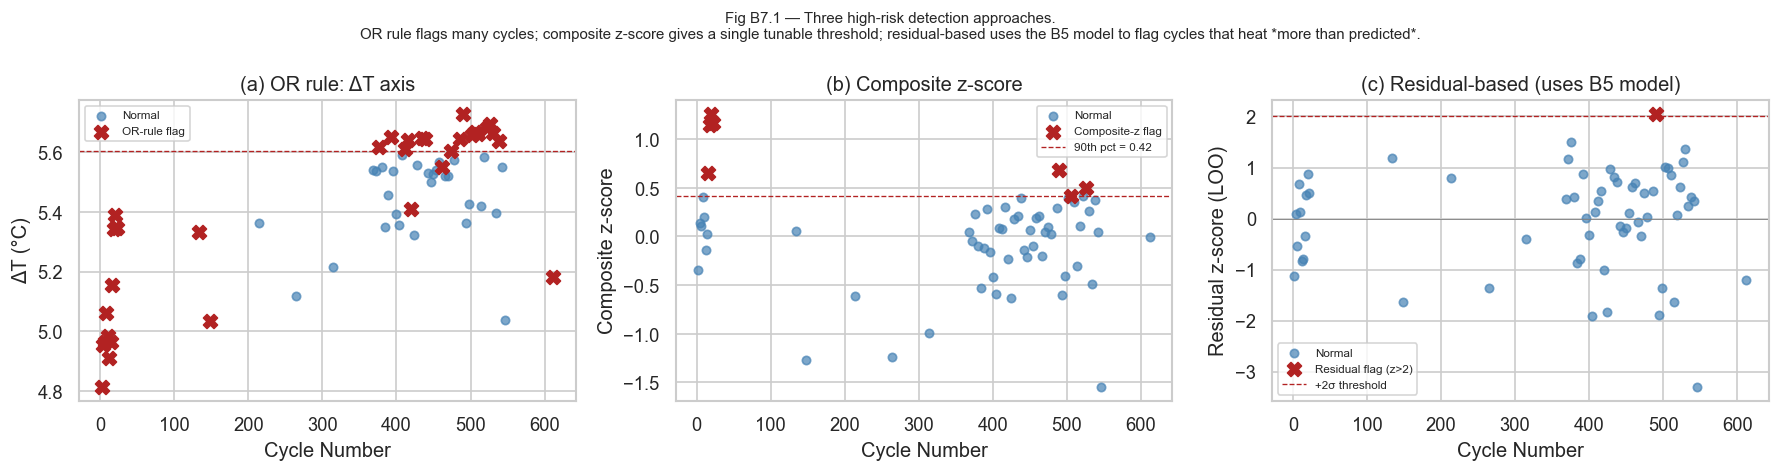

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1: ΔT vs cycle, OR rule
ax = axes[0]
ax.scatter(feat_df.loc[~feat_df['risk_OR'],'cycle'], feat_df.loc[~feat_df['risk_OR'],'delta_T'],
           color='steelblue', s=25, alpha=0.7, label='Normal')
ax.scatter(feat_df.loc[feat_df['risk_OR'],'cycle'],  feat_df.loc[feat_df['risk_OR'],'delta_T'],
           color='firebrick', marker='X', s=70, label='OR-rule flag')
ax.axhline(thr_delta_T, color='firebrick', linestyle='--', linewidth=0.8)
ax.set_xlabel('Cycle Number');  ax.set_ylabel('ΔT (°C)')
ax.set_title('(a) OR rule: ΔT axis');  ax.legend(fontsize=7)

# Panel 2: composite z-score
ax = axes[1]
ax.scatter(feat_df.loc[~feat_df['risk_composite'],'cycle'],
           feat_df.loc[~feat_df['risk_composite'],'composite_z'],
           color='steelblue', s=25, alpha=0.7, label='Normal')
ax.scatter(feat_df.loc[feat_df['risk_composite'],'cycle'],
           feat_df.loc[feat_df['risk_composite'],'composite_z'],
           color='firebrick', marker='X', s=70, label='Composite-z flag')
ax.axhline(COMPOSITE_THRESHOLD, color='firebrick', linestyle='--', linewidth=0.8,
           label=f'90th pct = {COMPOSITE_THRESHOLD:.2f}')
ax.set_xlabel('Cycle Number');  ax.set_ylabel('Composite z-score')
ax.set_title('(b) Composite z-score');  ax.legend(fontsize=7)

# Panel 3: residual-based
ax = axes[2]
ax.scatter(feat_df.loc[~feat_df['risk_residual'],'cycle'],
           feat_df.loc[~feat_df['risk_residual'],'residual_z'],
           color='steelblue', s=25, alpha=0.7, label='Normal')
ax.scatter(feat_df.loc[feat_df['risk_residual'],'cycle'],
           feat_df.loc[feat_df['risk_residual'],'residual_z'],
           color='firebrick', marker='X', s=70, label='Residual flag (z>2)')
ax.axhline(2.0, color='firebrick', linestyle='--', linewidth=0.8, label='+2σ threshold')
ax.axhline(0,  color='gray',     linestyle='-',  linewidth=0.5)
ax.set_xlabel('Cycle Number');  ax.set_ylabel('Residual z-score (LOO)')
ax.set_title('(c) Residual-based (uses B5 model)');  ax.legend(fontsize=7)

fig.suptitle('Fig B7.1 — Three high-risk detection approaches.\n'
             'OR rule flags many cycles; composite z-score gives a single '
             'tunable threshold; residual-based uses the B5 model to flag '
             'cycles that heat *more than predicted*.',
             fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / 'b7_high_risk_cycles.png', bbox_inches='tight')
plt.show()

**High-risk criteria — three approaches compared. Residual-based is recommended.**

- **OR rule (75th-percentile on ΔT or max dT/dt):** Flags ~46% of cycles. An alert that fires on half of all cycles is operationally useless.
- **Composite z-score (top 10%):** Single tunable threshold, balanced contribution from both indicators. Still threshold-based.
- **Residual-based (recommended):** Flags cycles where actual ΔT exceeds the Random Forest LOO prediction by more than 2σ — anomalous given operating conditions.

**Why residual-based:**
- Uses the B5 regressor directly — ties detection to the model.
- One-sided test, only flags over-heating.
- z > 2 has a clear statistical interpretation (~2.5% of cycles).
- Robust to ageing trends as residuals are de-trended by construction.

**Limitations.** n ≈ 60 cycles makes all thresholds fragile. These are monitoring heuristics — a real BMS must layer absolute manufacturer limits on top of any data-driven anomaly score.

# Part C — Ethics Discussion

*This section provides draft points for the 1-page ethics discussion in the report (Part A selected).*

---

## Data Bias and Representational Fairness

8000 balanced samples from five different soil types and eleven different crop kinds, all recorded within a single ambient temperature range (20–40 °C), make up the Crops dataset. Temperate or arid farming situations are not included in this range, which represents a subtropical or tropical climate. If the system were implemented without validation, a classifier trained on this data would generate untrustworthy recommendations for farmers in areas outside of this climatic envelope—a type of **geographic data bias** that may directly hurt the economy through crop failure.

Although balanced class counts lessen *within-dataset* fairness issues (no crop variety is consistently under-represented), balance by itself does not guarantee that the dataset accurately represents the distribution of farming conditions around the world. When the anticipated deployment is worldwide, it is ethically required to gather representative data from many regions.

## Algorithmic Fairness
The crop recommendation system recommends crops based on measurable soil and climate inputs.
Yet not all farmers have access to the necessary sensors required to measure this input (data)
(e.g. soil nitrogen analysers, humidity probes). Smallholder farmers in low-income regions — who may benefit most from precision agriculture — are least likely to run/own this technology in their farms. Deploying a system that requires expensive sensors may therefore **deepen the precision agriculture gap** rather than aiding it, raising questions of equitable access, and therefore the collection of data.

## Real-World Misuse

A crop recommendation classifier presented as authoritative could be misused in several ways:
- **Over-reliance:** A farmer following machine learning recommendations without consulting an agronomist may ignore local/basic ecological knowledge (e.g. pest cycles, water table depth) that the model cannot acknowledge.
- **Monoculture risk:** If the model systematically recommends high-yield cash crops, widespread adoption could reduce biodiversity and increase systemic agricultural risk.
- **Accountability gap:** When a recommended crop fails, liability is unclear — the model developer, the platform provider, or the farmer. Clear terms of use and human-in-the-loop decision processes are needed.

## Data Privacy

Farm-level data (location, soil composition, yield) is commercially sensitive and could be exploited by agribusiness companies or commodity traders if not protected. Farmers should retain ownership of their data, and any Machine Learning platform collecting this data should comply with applicable data protection law (e.g. GDPR in the EU).

## Mitigation



Responsible deployment would require: geographic validation studies before release; accessible low-cost sensor alternatives or offline lookup tables for data-sparse regions; transparent uncertainty communication (e.g. confidence intervals on recommendations); and clear human-override provision.